In [4]:
# ============================================================================
# IEEE ACCESS PAPER: HiENBERT - Hybrid Indic-English BERT for Multi-Task 
# Complaint Classification - OPTIMIZED VERSION
# ============================================================================
# CELL 1: IMPORTS AND SYSTEM SETUP - OPTIMIZED
# ============================================================================

import os
import sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import pickle
import json
import random
from datetime import datetime
import time

# PyTorch imports
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.cuda.amp import GradScaler, autocast

# Transformers
from transformers import (
    AutoTokenizer, 
    AutoModel,
    get_cosine_schedule_with_warmup,
    get_linear_schedule_with_warmup
)

# Scikit-learn
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, 
    f1_score, 
    precision_score, 
    recall_score,
    classification_report, 
    confusion_matrix,
    balanced_accuracy_score,
    cohen_kappa_score,
    matthews_corrcoef
)

# Set random seeds for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = True

set_seed(42)

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\n{'='*80}")
print(f"SYSTEM INFORMATION")
print(f"{'='*80}")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA device: {torch.cuda.get_device_name(0)}")
    print(f"CUDA memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
    torch.backends.cudnn.benchmark = True
print(f"Using device: {device}")
print(f"{'='*80}\n")


SYSTEM INFORMATION
PyTorch version: 2.6.0+cu126
CUDA available: True
CUDA device: NVIDIA GeForce RTX 3070
CUDA memory: 8.59 GB
Using device: cuda



In [ ]:
# ============================================================================
# CELL 2: OPTIMIZED CONFIGURATION - FASTER TRAINING
# ============================================================================

class Config:
    """Optimized configuration settings for HiENBERT training"""
    
    # =========================================================================
    # BASE MODEL
    # =========================================================================
    BASE_MODEL = 'xlm-roberta'
    XLMBERT_PATH = "xlm-roberta-base"
    
    # =========================================================================
    # PROJECT ROOT DIRECTORY
    # =========================================================================
    PROJECT_DIR = os.getcwd()
    
    # =========================================================================
    # INPUT DATASET DIRECTORY
    # =========================================================================
    DATA_DIR = os.path.join(PROJECT_DIR, "Common_Dataset")
    TRAIN_PATH = os.path.join(DATA_DIR, "train.csv")
    DEV_PATH = os.path.join(DATA_DIR, "dev.csv")
    TEST_PATH = os.path.join(DATA_DIR, "test.csv")

    
    # =========================================================================
    # OUTPUT DIRECTORY
    # =========================================================================
    BASE_DIR = os.path.join(PROJECT_DIR, "hienbert_results_CommonDataset")
    MODEL_DIR = os.path.join(BASE_DIR, "models")
    VISUALIZATION_DIR = os.path.join(BASE_DIR, "visualizations")
    LOG_DIR = os.path.join(BASE_DIR, "logs")
    RESULTS_DIR = os.path.join(BASE_DIR, "results")
    CHECKPOINT_DIR = os.path.join(BASE_DIR, "checkpoints")
    SHAP_DIR = os.path.join(BASE_DIR, "shap_explanations")
    
    for dir_path in [BASE_DIR, MODEL_DIR, VISUALIZATION_DIR, LOG_DIR,
                     RESULTS_DIR, CHECKPOINT_DIR, SHAP_DIR]:
        os.makedirs(dir_path, exist_ok=True)
    SHAP_DIR = os.path.join(
    RESULTS_DIR,
    "shap_explanations"
)
    # =========================================================================
    # OPTIMIZED TRAINING PARAMETERS - FASTER
    # =========================================================================
    MAX_LENGTH = 128
    BATCH_SIZE = 32  # Increased for faster training
    EPOCHS = 15      # Reduced epochs - early stopping will handle
    LEARNING_RATE = 2e-5  # Slightly higher for faster convergence
    DROPOUT = 0.3
    WEIGHT_DECAY = 0.01
    GRADIENT_ACCUMULATION_STEPS = 1  # Effective batch size = 64 * 2 = 128
    WARMUP_RATIO = 0.1
    
    # =========================================================================
    # OPTIMIZED TRAINING SETTINGS
    # =========================================================================
    USE_AMP = True
    NUM_WORKERS = 4  # For faster data loading
    PIN_MEMORY = True
    
    # =========================================================================
    # DEVICE
    # =========================================================================
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    SEED = 42
    
    # =========================================================================
    # HUGGING FACE TOKEN
    # =========================================================================
    HF_TOKEN = os.getenv("HF_TOKEN")


def get_model_path():
    return Config.XLMBERT_PATH


print("=" * 80)
print("OPTIMIZED HIENBERT CONFIGURATION")
print("=" * 80)
print(f"\n[BATCH SIZE] {Config.BATCH_SIZE} (Effective: {Config.BATCH_SIZE * Config.GRADIENT_ACCUMULATION_STEPS})")
print(f"[EPOCHS] {Config.EPOCHS}")
print(f"[LEARNING RATE] {Config.LEARNING_RATE}")
print(f"[NUM WORKERS] {Config.NUM_WORKERS}")
print(f"[DEVICE] {Config.DEVICE}")
print("=" * 80)

OPTIMIZED HIENBERT CONFIGURATION

[BATCH SIZE] 32 (Effective: 32)
[EPOCHS] 15
[LEARNING RATE] 2e-05
[NUM WORKERS] 4
[DEVICE] cuda


In [6]:
# ============================================================================
# CELL 3: OPTIMIZED DATA LOADING
# ============================================================================

class OptimizedDataLoader:
    """Load and analyze balanced dataset - OPTIMIZED"""
    
    def __init__(self):
        self.train_df = None
        self.dev_df = None
        self.test_df = None
    
    def load_data(self):
        print("Loading datasets...")
        self.train_df = pd.read_csv(Config.TRAIN_PATH)
        self.dev_df = pd.read_csv(Config.DEV_PATH)
        self.test_df = pd.read_csv(Config.TEST_PATH)
        print(f"Train: {len(self.train_df)}, Dev: {len(self.dev_df)}, Test: {len(self.test_df)}")
        return self.train_df, self.dev_df, self.test_df
    
    def analyze_distribution(self, df, label_col, title=""):
        class_counts = df[label_col].value_counts()
        class_percentages = df[label_col].value_counts(normalize=True) * 100
        print(f"\n{'='*60}")
        print(f"Class Distribution - {title}")
        print(f"{'='*60}")
        for cls, count in class_counts.items():
            print(f"  {cls}: {count} ({class_percentages[cls]:.2f}%)")
        return class_counts
    
    def analyze_all(self):
        self.load_data()
        print("\n" + "="*80)
        print("DATASET ANALYSIS")
        print("="*80)
        self.analyze_distribution(self.train_df, 'primary_category', 'Primary Categories')
        self.analyze_distribution(self.train_df, 'Severity', 'Severity')
        return self.train_df, self.dev_df, self.test_df

# Load data
data_loader = OptimizedDataLoader()
train_df, dev_df, test_df = data_loader.load_data()

Loading datasets...
Train: 14165, Dev: 3035, Test: 3036


In [7]:
# ============================================================================
# CELL 4: OPTIMIZED DATA PREPROCESSING
# ============================================================================

class OptimizedPreprocessor:
    """Optimized data preprocessing with efficient text handling"""
    
    def __init__(self):
        self.le_primary = LabelEncoder()
        self.le_subcat = LabelEncoder()
        self.le_severity = LabelEncoder()
        
        self.column_mapping = {
            'primary_category': 'category_primary',
            'secondary_category': 'category_secondary',
            'Severity': 'severity',
            'Complaint_Title': 'complaint_title',
            'Text_en': 'text_en',
            'Text_hi': 'Hindi',
            'Text_hinglish': 'Hinglish'
        }
    
    def rename_columns(self, df):
        rename_dict = {k: v for k, v in self.column_mapping.items() if k in df.columns}
        if rename_dict:
            df = df.rename(columns=rename_dict)
        return df
    
    def preprocess_text(self, df):
        df = self.rename_columns(df)
        
        # Fill NaN values efficiently
        text_cols = ['complaint_title', 'text_en', 'Hindi', 'Hinglish']
        for col in text_cols:
            if col in df.columns:
                df[col] = df[col].fillna('').astype(str)
        
        # Combine text efficiently
        available_cols = [col for col in text_cols if col in df.columns]
        if available_cols:
            df["text"] = df[available_cols].agg(" ".join, axis=1)
            df["text"] = df["text"].str.replace(r"\s+", " ", regex=True).str.strip()
        
        df = df.dropna(subset=["category_primary", "category_secondary", "severity"])
        return df.reset_index(drop=True)
    
    def prepare_labels(self, train_df, dev_df, test_df):
        print("\nPreparing labels...")
        
        self.le_primary.fit(train_df['category_primary'])
        self.le_subcat.fit(train_df['category_secondary'])
        self.le_severity.fit(train_df['severity'])
        
        print(f"Primary: {len(self.le_primary.classes_)}, "
              f"Subcat: {len(self.le_subcat.classes_)}, "
              f"Severity: {len(self.le_severity.classes_)}")
        
        for df in [train_df, dev_df, test_df]:
            df["primary_label"] = self.le_primary.transform(df["category_primary"])
            df["subcat_label"] = self.le_subcat.transform(df["category_secondary"])
            df["severity_label"] = self.le_severity.transform(df["severity"])
            df["sentiment_score"] = 0.0
        
        return train_df, dev_df, test_df
    
    def process_data(self, train_df, dev_df, test_df):
        print("\nPreprocessing text...")
        train_df = self.preprocess_text(train_df)
        dev_df = self.preprocess_text(dev_df)
        test_df = self.preprocess_text(test_df)
        
        train_df, dev_df, test_df = self.prepare_labels(train_df, dev_df, test_df)
        
        print(f"\nFinal: Train {len(train_df)}, Dev {len(dev_df)}, Test {len(test_df)}")
        return train_df, dev_df, test_df

# Process data
preprocessor = OptimizedPreprocessor()
train_df, dev_df, test_df = preprocessor.process_data(train_df, dev_df, test_df)
print("\n✅ Data preprocessing completed")


Preprocessing text...

Preparing labels...
Primary: 8, Subcat: 24, Severity: 3

Final: Train 14165, Dev 3035, Test 3036

✅ Data preprocessing completed


In [8]:
# ============================================================================
# CELL 5: OPTIMIZED DATASET CLASS
# ============================================================================

class OptimizedComplaintDataset(Dataset):
    """Optimized dataset with efficient tokenization"""
    
    def __init__(self, df, tokenizer, max_length=128):
        self.texts = df["text"].astype(str).tolist()
        self.primary = torch.tensor(df["primary_label"].values, dtype=torch.long)
        self.subcat = torch.tensor(df["subcat_label"].values, dtype=torch.long)
        self.severity = torch.tensor(df["severity_label"].values, dtype=torch.long)
        self.sentiment = torch.zeros(len(df), dtype=torch.float)
        self.tokenizer = tokenizer
        self.max_length = max_length
    
    def __len__(self):
        return len(self.texts)
    
    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )
        return {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "primary": self.primary[idx],
            "subcat": self.subcat[idx],
            "severity": self.severity[idx],
            "sentiment": self.sentiment[idx]
        }


def create_optimized_dataloaders(train_df, dev_df, test_df, tokenizer):
    """Create optimized dataloaders with multiple workers"""
    print("\nCreating optimized dataloaders...")
    
    train_dataset = OptimizedComplaintDataset(train_df, tokenizer, Config.MAX_LENGTH)
    dev_dataset = OptimizedComplaintDataset(dev_df, tokenizer, Config.MAX_LENGTH)
    test_dataset = OptimizedComplaintDataset(test_df, tokenizer, Config.MAX_LENGTH)
    
    train_loader = DataLoader(
        train_dataset,
        batch_size=Config.BATCH_SIZE,
        shuffle=True,
        num_workers=Config.NUM_WORKERS,
        pin_memory=Config.PIN_MEMORY,
        drop_last=False,
        prefetch_factor=4
    )
    
    dev_loader = DataLoader(
        dev_dataset,
        batch_size=Config.BATCH_SIZE * 2,
        shuffle=False,
        num_workers=Config.NUM_WORKERS // 2,
        pin_memory=Config.PIN_MEMORY
    )
    
    test_loader = DataLoader(
        test_dataset,
        batch_size=Config.BATCH_SIZE * 2,
        shuffle=False,
        num_workers=Config.NUM_WORKERS // 2,
        pin_memory=Config.PIN_MEMORY
    )
    
    print(f"Train batches: {len(train_loader)}, Dev: {len(dev_loader)}, Test: {len(test_loader)}")
    return train_loader, dev_loader, test_loader

print("✅ Dataset class defined")

✅ Dataset class defined


In [6]:
# ============================================================================
# CELL 6: OPTIMIZED HIENBERT MODEL
# ============================================================================

class OptimizedHiEnBERT(nn.Module):
    """Optimized HiENBERT model with efficient architecture"""
    
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.2):
        super().__init__()
        self.base = base_model
        hidden_size = base_model.config.hidden_size
        
        self.dropout = nn.Dropout(dropout)
        
        # Single shared layer for efficiency
        self.shared = nn.Linear(hidden_size, hidden_size)
        self.gelu = nn.GELU()
        
        # Task-specific heads
        self.fc_primary = nn.Linear(hidden_size, n_primary)
        self.fc_subcat = nn.Linear(hidden_size, n_subcat)
        self.fc_severity = nn.Linear(hidden_size, n_severity)
        
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        self.hidden_size = hidden_size
        
        self._init_weights()
    
    def _init_weights(self):
        for module in [self.fc_primary, self.fc_subcat, self.fc_severity, self.shared]:
            if hasattr(module, 'weight'):
                nn.init.xavier_uniform_(module.weight)
            if hasattr(module, 'bias') and module.bias is not None:
                nn.init.zeros_(module.bias)
    
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls_embedding = outputs.last_hidden_state[:, 0, :]
        
        # Shared representation
        x = self.gelu(self.shared(cls_embedding))
        x = self.dropout(x)
        
        primary_logits = self.fc_primary(x)
        subcat_logits = self.fc_subcat(x)
        severity_logits = self.fc_severity(x)
        
        return primary_logits, subcat_logits, severity_logits
    
    def get_embeddings(self, input_ids, attention_mask):
        with torch.no_grad():
            outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
            return outputs.last_hidden_state[:, 0, :]

In [7]:
# ============================================================================
# CELL 7: LOAD BASE MODEL
# ============================================================================

def load_base_model():
    model_path = get_model_path()
    print(f"Loading base model: {model_path}")
    
    tokenizer = AutoTokenizer.from_pretrained(
        model_path,
        token=Config.HF_TOKEN,
        use_fast=True  # Fast tokenizer for speed
    )
    
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    
    base_model = AutoModel.from_pretrained(
        model_path,
        token=Config.HF_TOKEN
    )
    
    print(f"Vocab size: {tokenizer.vocab_size}, Hidden: {base_model.config.hidden_size}")
    return base_model, tokenizer

# Load model
base_model, tokenizer = load_base_model()
base_model = base_model.to(Config.DEVICE)

# Create optimized model
n_primary = len(preprocessor.le_primary.classes_)
n_subcat = len(preprocessor.le_subcat.classes_)
n_severity = len(preprocessor.le_severity.classes_)

model = OptimizedHiEnBERT(
    base_model=base_model,
    n_primary=n_primary,
    n_subcat=n_subcat,
    n_severity=n_severity,
    dropout=Config.DROPOUT
).to(Config.DEVICE)

print(f"\n✅ Model loaded: {sum(p.numel() for p in model.parameters()):,} parameters")

Loading base model: xlm-roberta-base


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 13718.14it/s]
[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Vocab size: 250002, Hidden: 768

✅ Model loaded: 278,661,155 parameters


In [8]:
# ============================================================================
# CELL 8: FIXED OPTIMIZED TRAINING FUNCTIONS
# ============================================================================

class MultiTaskLoss(nn.Module):
    """Efficient multi-task loss"""
    def __init__(self):
        super().__init__()
        self.primary_loss = nn.CrossEntropyLoss()
        self.subcat_loss = nn.CrossEntropyLoss()
        self.severity_loss = nn.CrossEntropyLoss()
        
        self.primary_weight = 1.0
        self.subcat_weight = 1.0
        self.severity_weight = 0.5
    
    def forward(self, p1, p2, p3, y1, y2, y3):
        loss1 = self.primary_loss(p1, y1)
        loss2 = self.subcat_loss(p2, y2)
        loss3 = self.severity_loss(p3, y3)
        
        total = self.primary_weight * loss1 + self.subcat_weight * loss2 + self.severity_weight * loss3
        return total, {'primary': loss1.item(), 'subcat': loss2.item(), 'severity': loss3.item()}

criterion = MultiTaskLoss()


class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.001, mode='max'):
        self.patience = patience
        self.min_delta = min_delta
        self.mode = mode
        self.counter = 0
        self.best_score = None
        self.early_stop = False
    
    def __call__(self, score):
        if self.best_score is None:
            self.best_score = score
            return False
        
        if self.mode == 'max':
            improvement = score - self.best_score > self.min_delta
        else:
            improvement = self.best_score - score > self.min_delta
        
        if improvement:
            self.best_score = score
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        return self.early_stop


def train_epoch_optimized(model, dataloader, optimizer, scheduler, criterion, device, scaler=None):
    """FIXED: Optimized training loop - properly handles gradient accumulation"""
    model.train()
    total_loss = 0
    all_preds = []
    all_labels = []
    task_losses = {'primary': 0, 'subcat': 0, 'severity': 0}
    
    optimizer.zero_grad()  # Initialize with zero grad
    
    progress_bar = tqdm(dataloader, desc='Training', leave=False)
    
    for batch_idx, batch in enumerate(progress_bar):
        input_ids = batch['input_ids'].to(device, non_blocking=True)
        attention_mask = batch['attention_mask'].to(device, non_blocking=True)
        y_primary = batch['primary'].to(device, non_blocking=True)
        y_subcat = batch['subcat'].to(device, non_blocking=True)
        y_severity = batch['severity'].to(device, non_blocking=True)
        sentiment = batch['sentiment'].to(device, non_blocking=True)
        
        # Forward pass with mixed precision
        if scaler is not None:
            with autocast():
                p1, p2, p3 = model(input_ids, attention_mask, sentiment)
                loss, loss_dict = criterion(p1, p2, p3, y_primary, y_subcat, y_severity)
        else:
            p1, p2, p3 = model(input_ids, attention_mask, sentiment)
            loss, loss_dict = criterion(p1, p2, p3, y_primary, y_subcat, y_severity)
        
        # Normalize loss for gradient accumulation
        loss = loss / Config.GRADIENT_ACCUMULATION_STEPS
        
        # Backward pass
        if scaler is not None:
            scaler.scale(loss).backward()
        else:
            loss.backward()
        
        # Update weights only after accumulation steps
        if (batch_idx + 1) % Config.GRADIENT_ACCUMULATION_STEPS == 0:
            if scaler is not None:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer)
                scaler.update()
            else:
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)
        
        total_loss += loss.item() * Config.GRADIENT_ACCUMULATION_STEPS
        
        for key in task_losses:
            task_losses[key] += loss_dict.get(key, 0)
        
        preds = torch.argmax(p1, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y_primary.cpu().numpy())
        
        # Update progress bar with current batch accuracy
        current_acc = accuracy_score(all_labels[-input_ids.size(0):], preds.cpu().numpy())
        progress_bar.set_postfix({
            'loss': f'{loss.item() * Config.GRADIENT_ACCUMULATION_STEPS:.3f}',
            'acc': f'{current_acc:.3f}',
            'batch': f'{batch_idx+1}/{len(dataloader)}'
        })
    
    avg_loss = total_loss / len(dataloader)
    acc = accuracy_score(all_labels, all_preds)
    bal_acc = balanced_accuracy_score(all_labels, all_preds)
    
    for key in task_losses:
        task_losses[key] /= len(dataloader)
    
    return avg_loss, acc, bal_acc, task_losses


def evaluate_optimized(model, dataloader, device, return_predictions=False):
    """Fixed optimized evaluation"""
    model.eval()
    all_preds = []
    all_labels = []
    all_confidences = []
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc='Evaluating', leave=False):
            input_ids = batch['input_ids'].to(device, non_blocking=True)
            attention_mask = batch['attention_mask'].to(device, non_blocking=True)
            sentiment = batch['sentiment'].to(device, non_blocking=True)
            
            p1, _, _ = model(input_ids, attention_mask, sentiment)
            probs = torch.softmax(p1, dim=1)
            preds = torch.argmax(p1, dim=1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(batch['primary'].cpu().numpy())
            all_confidences.extend(probs.max(dim=1)[0].cpu().numpy())
    
    metrics = {
        'accuracy': accuracy_score(all_labels, all_preds),
        'balanced_accuracy': balanced_accuracy_score(all_labels, all_preds),
        'f1_macro': f1_score(all_labels, all_preds, average='macro', zero_division=0),
        'f1_weighted': f1_score(all_labels, all_preds, average='weighted', zero_division=0),
        'precision': precision_score(all_labels, all_preds, average='weighted', zero_division=0),
        'recall': recall_score(all_labels, all_preds, average='weighted', zero_division=0),
        'cohen_kappa': cohen_kappa_score(all_labels, all_preds),
        'mcc': matthews_corrcoef(all_labels, all_preds),
        'confidences': np.array(all_confidences)
    }
    
    if return_predictions:
        return metrics, all_preds, all_labels
    return metrics

In [9]:
# ============================================================================
# CELL 9: FIXED - CREATE OPTIMIZED DATALOADERS
# ============================================================================

# FIRST, let's test with a smaller batch size to ensure it works
# Override Config for testing
Config.BATCH_SIZE = 32  # Reduce batch size for stability
Config.GRADIENT_ACCUMULATION_STEPS = 1  # Start with no accumulation
Config.NUM_WORKERS = 0  # Use 0 for debugging (will show errors)

print(f"USING: Batch Size={Config.BATCH_SIZE}, Accumulation={Config.GRADIENT_ACCUMULATION_STEPS}, Workers={Config.NUM_WORKERS}")

# FIXED: Create dataloaders with conditional prefetch_factor
def create_fixed_dataloaders(train_df, dev_df, test_df, tokenizer):
    """Create dataloaders with proper handling of prefetch_factor"""
    print("\nCreating optimized dataloaders...")
    
    train_dataset = OptimizedComplaintDataset(train_df, tokenizer, Config.MAX_LENGTH)
    dev_dataset = OptimizedComplaintDataset(dev_df, tokenizer, Config.MAX_LENGTH)
    test_dataset = OptimizedComplaintDataset(test_df, tokenizer, Config.MAX_LENGTH)
    
    # Common DataLoader arguments
    common_args = {
        'batch_size': Config.BATCH_SIZE,
        'shuffle': True,
        'num_workers': Config.NUM_WORKERS,
        'pin_memory': Config.PIN_MEMORY,
        'drop_last': False
    }
    
    # Only add prefetch_factor if num_workers > 0
    if Config.NUM_WORKERS > 0:
        common_args['prefetch_factor'] = 4
    
    train_loader = DataLoader(train_dataset, **common_args)
    
    # Validation loader
    val_args = {
        'batch_size': Config.BATCH_SIZE * 2,
        'shuffle': False,
        'num_workers': Config.NUM_WORKERS // 2 if Config.NUM_WORKERS > 1 else 0,
        'pin_memory': Config.PIN_MEMORY
    }
    if Config.NUM_WORKERS > 1:
        val_args['prefetch_factor'] = 2
    
    dev_loader = DataLoader(dev_dataset, **val_args)
    test_loader = DataLoader(test_dataset, **val_args)
    
    print(f"Train batches: {len(train_loader)}, Dev: {len(dev_loader)}, Test: {len(test_loader)}")
    return train_loader, dev_loader, test_loader

# Create dataloaders
train_loader, dev_loader, test_loader = create_fixed_dataloaders(
    train_df, dev_df, test_df, tokenizer
)

# Test one batch to ensure it works
print("\nTesting data loader...")
test_batch = next(iter(train_loader))
print(f"Input shape: {test_batch['input_ids'].shape}")
print(f"Labels: {test_batch['primary'].shape}")
print("✅ Data loader working!")

# Setup optimizer
optimizer = AdamW(
    model.parameters(),
    lr=Config.LEARNING_RATE,
    weight_decay=Config.WEIGHT_DECAY,
    betas=(0.9, 0.999),
    eps=1e-8
)

total_steps = len(train_loader) * Config.EPOCHS // Config.GRADIENT_ACCUMULATION_STEPS
scheduler = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(Config.WARMUP_RATIO * total_steps),
    num_training_steps=total_steps
)

scaler = GradScaler() if Config.USE_AMP and torch.cuda.is_available() else None
early_stopping = EarlyStopping(patience=5, mode='max')

print(f"\nTraining setup:")
print(f"  Total batches per epoch: {len(train_loader)}")
print(f"  Total steps: {total_steps}")
print(f"  Warmup steps: {int(Config.WARMUP_RATIO * total_steps)}")
print(f"  Effective batch size: {Config.BATCH_SIZE * Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"  Mixed precision: {scaler is not None}")

USING: Batch Size=32, Accumulation=1, Workers=0

Creating optimized dataloaders...
Train batches: 443, Dev: 48, Test: 48

Testing data loader...
Input shape: torch.Size([32, 128])
Labels: torch.Size([32])
✅ Data loader working!

Training setup:
  Total batches per epoch: 443
  Total steps: 6645
  Warmup steps: 664
  Effective batch size: 32
  Mixed precision: True


In [10]:
# ============================================================================
# CELL 10: FIXED TRAINING LOOP
# ============================================================================

train_history = []
val_history = []
best_val_f1 = 0
best_val_balanced_acc = 0

print("\n" + "="*80)
print(f"TRAINING HIENBERT WITH {Config.BASE_MODEL.upper()}")
print("="*80 + "\n")

start_time = time.time()

# Try a single batch first to test
print("\nTesting forward pass...")
test_batch = next(iter(train_loader))
input_ids = test_batch['input_ids'].to(Config.DEVICE)
attention_mask = test_batch['attention_mask'].to(Config.DEVICE)
sentiment = test_batch['sentiment'].to(Config.DEVICE)
p1, p2, p3 = model(input_ids, attention_mask, sentiment)
print(f"Output shapes: {p1.shape}, {p2.shape}, {p3.shape}")
print("✅ Forward pass working!")

# Now train
for epoch in range(Config.EPOCHS):
    epoch_start = time.time()
    print(f"\nEpoch {epoch+1}/{Config.EPOCHS}")
    print("-"*50)
    
    # Training
    try:
        train_loss, train_acc, train_bal_acc, task_losses = train_epoch_optimized(
            model, train_loader, optimizer, scheduler, criterion, Config.DEVICE, scaler
        )
    except Exception as e:
        print(f"Error in training: {e}")
        import traceback
        traceback.print_exc()
        break
    
    # Validation
    val_metrics = evaluate_optimized(model, dev_loader, Config.DEVICE)
    val_acc = val_metrics['accuracy']
    val_bal_acc = val_metrics['balanced_accuracy']
    val_f1 = val_metrics['f1_weighted']
    
    epoch_time = time.time() - epoch_start
    
    train_history.append({
        'loss': train_loss, 'acc': train_acc, 'balanced_acc': train_bal_acc,
        'task_losses': task_losses, 'lr': scheduler.get_last_lr()[0], 'time': epoch_time
    })
    
    val_history.append({
        'val_acc': val_acc, 'val_bal_acc': val_bal_acc, 'val_f1': val_f1,
        'metrics': val_metrics, 'time': epoch_time
    })
    
    print(f"Train Loss: {train_loss:.4f} | Acc: {train_acc:.4f} | Bal Acc: {train_bal_acc:.4f}")
    print(f"Val Acc: {val_acc:.4f} | Bal Acc: {val_bal_acc:.4f} | F1: {val_f1:.4f}")
    print(f"Task Losses: Primary={task_losses['primary']:.3f}, Subcat={task_losses['subcat']:.3f}, Severity={task_losses['severity']:.3f}")
    print(f"Epoch Time: {epoch_time:.1f}s")
    
    # Save best model
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_val_balanced_acc = val_bal_acc
        checkpoint = {
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_f1': val_f1,
            'val_balanced_acc': val_bal_acc,
            'train_history': train_history,
            'val_history': val_history,
            'label_encoders': {
                'primary': preprocessor.le_primary,
                'subcat': preprocessor.le_subcat,
                'severity': preprocessor.le_severity
            }
        }
        torch.save(checkpoint, f"{Config.MODEL_DIR}/best_hienbert_model.pt")
        print(f"✓ New best model saved! F1: {val_f1:.4f}")
    
    if early_stopping(val_f1):
        print(f"Early stopping triggered after {epoch+1} epochs")
        break

total_time = time.time() - start_time
print(f"\n✅ Training completed in {total_time/60:.1f} minutes")


TRAINING HIENBERT WITH XLM-ROBERTA


Testing forward pass...
Output shapes: torch.Size([32, 8]), torch.Size([32, 24]), torch.Size([32, 3])
✅ Forward pass working!

Epoch 1/15
--------------------------------------------------


Train Loss: 4.7138 | Acc: 0.4311 | Bal Acc: 0.4180
Val Acc: 0.8544 | Bal Acc: 0.8603 | F1: 0.8538
Task Losses: Primary=1.562, Subcat=2.611, Severity=1.082
Epoch Time: 355.3s
✓ New best model saved! F1: 0.8538

Epoch 2/15
--------------------------------------------------


Train Loss: 1.8925 | Acc: 0.8681 | Bal Acc: 0.8664
Val Acc: 0.8956 | Bal Acc: 0.8931 | F1: 0.8951
Task Losses: Primary=0.475, Subcat=1.031, Severity=0.774
Epoch Time: 357.4s
✓ New best model saved! F1: 0.8951

Epoch 3/15
--------------------------------------------------


Train Loss: 1.1828 | Acc: 0.9108 | Bal Acc: 0.9097
Val Acc: 0.9100 | Bal Acc: 0.9121 | F1: 0.9096
Task Losses: Primary=0.309, Subcat=0.623, Severity=0.502
Epoch Time: 357.4s
✓ New best model saved! F1: 0.9096

Epoch 4/15
--------------------------------------------------


Train Loss: 0.8903 | Acc: 0.9329 | Bal Acc: 0.9323
Val Acc: 0.9209 | Bal Acc: 0.9254 | F1: 0.9212
Task Losses: Primary=0.229, Subcat=0.467, Severity=0.390
Epoch Time: 357.2s
✓ New best model saved! F1: 0.9212

Epoch 5/15
--------------------------------------------------


Train Loss: 0.7105 | Acc: 0.9451 | Bal Acc: 0.9450
Val Acc: 0.9255 | Bal Acc: 0.9280 | F1: 0.9254
Task Losses: Primary=0.178, Subcat=0.377, Severity=0.310
Epoch Time: 357.2s
✓ New best model saved! F1: 0.9254

Epoch 6/15
--------------------------------------------------


... (6 outputs left out)

Train Loss: 0.1337 | Acc: 0.9915 | Bal Acc: 0.9915
Val Acc: 0.9357 | Bal Acc: 0.9378 | F1: 0.9357
Task Losses: Primary=0.028, Subcat=0.070, Severity=0.072
Epoch Time: 357.4s
✓ New best model saved! F1: 0.9357

Epoch 13/15
--------------------------------------------------


Train Loss: 0.1099 | Acc: 0.9943 | Bal Acc: 0.9944
Val Acc: 0.9328 | Bal Acc: 0.9341 | F1: 0.9328
Task Losses: Primary=0.022, Subcat=0.059, Severity=0.059
Epoch Time: 356.8s

Epoch 14/15
--------------------------------------------------


Train Loss: 0.0993 | Acc: 0.9944 | Bal Acc: 0.9945
Val Acc: 0.9334 | Bal Acc: 0.9354 | F1: 0.9334
Task Losses: Primary=0.020, Subcat=0.053, Severity=0.053
Epoch Time: 357.0s

Epoch 15/15
--------------------------------------------------


Train Loss: 0.0912 | Acc: 0.9954 | Bal Acc: 0.9954
Val Acc: 0.9338 | Bal Acc: 0.9357 | F1: 0.9338
Task Losses: Primary=0.019, Subcat=0.048, Severity=0.050
Epoch Time: 357.4s

✅ Training completed in 90.0 minutes


In [11]:
# ============================================================================
# CELL 11: FINAL TEST EVALUATION
# ============================================================================

print("\n" + "="*80)
print("FINAL TEST EVALUATION")
print("="*80)

# Check if model exists
checkpoint_path = f"{Config.MODEL_DIR}/best_hienbert_model.pt"
if os.path.exists(checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location=Config.DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    print("✅ Loaded best model")
else:
    print("⚠️ Using current model (no checkpoint found)")

model.eval()

test_metrics, test_preds, test_labels = evaluate_optimized(
    model, test_loader, Config.DEVICE, return_predictions=True
)

print("\nTEST RESULTS:")
print("-"*50)
for metric, value in test_metrics.items():
    if not isinstance(value, np.ndarray):
        print(f"  {metric}: {value:.4f}")

# Save results
test_results = {
    'test_metrics': {k: float(v) for k, v in test_metrics.items() if not isinstance(v, np.ndarray)},
    'best_val_f1': float(best_val_f1),
    'best_val_balanced_acc': float(best_val_balanced_acc),
    'base_model': Config.BASE_MODEL
}

with open(f"{Config.RESULTS_DIR}/test_results.json", "w") as f:
    json.dump(test_results, f, indent=2)

print(f"\n✅ Results saved to {Config.RESULTS_DIR}")


FINAL TEST EVALUATION
✅ Loaded best model



TEST RESULTS:
--------------------------------------------------
  accuracy: 0.9328
  balanced_accuracy: 0.9357
  f1_macro: 0.9342
  f1_weighted: 0.9328
  precision: 0.9332
  recall: 0.9328
  cohen_kappa: 0.9224
  mcc: 0.9225

✅ Results saved to C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results


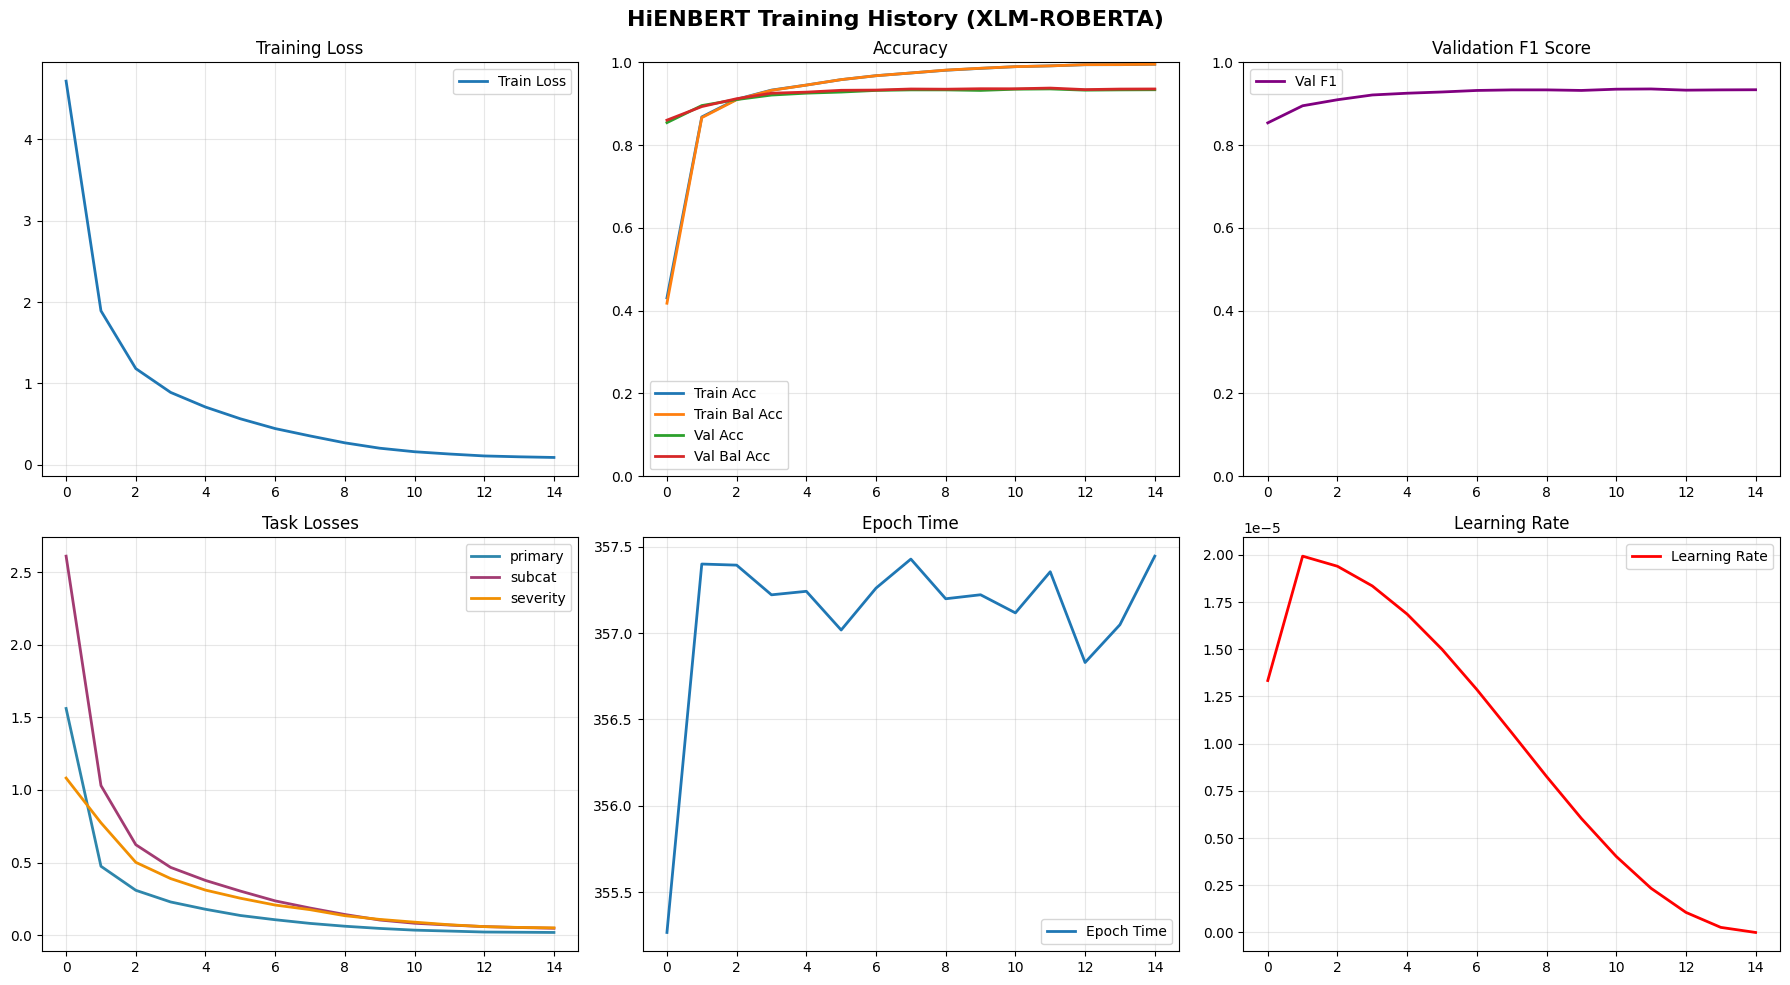

In [12]:
# ============================================================================
# CELL 12: TRAINING HISTORY VISUALIZATION
# ============================================================================

def plot_optimized_history(train_history, val_history, save_path=None):
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    
    # Training loss
    axes[0, 0].plot([h['loss'] for h in train_history], label='Train Loss', linewidth=2)
    axes[0, 0].set_title('Training Loss')
    axes[0, 0].grid(True, alpha=0.3)
    axes[0, 0].legend()
    
    # Accuracy
    axes[0, 1].plot([h['acc'] for h in train_history], label='Train Acc', linewidth=2)
    axes[0, 1].plot([h['balanced_acc'] for h in train_history], label='Train Bal Acc', linewidth=2)
    axes[0, 1].plot([h['val_acc'] for h in val_history], label='Val Acc', linewidth=2)
    axes[0, 1].plot([h['val_bal_acc'] for h in val_history], label='Val Bal Acc', linewidth=2)
    axes[0, 1].set_title('Accuracy')
    axes[0, 1].set_ylim(0, 1)
    axes[0, 1].grid(True, alpha=0.3)
    axes[0, 1].legend()
    
    # F1 Score
    axes[0, 2].plot([h['val_f1'] for h in val_history], label='Val F1', linewidth=2, color='purple')
    axes[0, 2].set_title('Validation F1 Score')
    axes[0, 2].set_ylim(0, 1)
    axes[0, 2].grid(True, alpha=0.3)
    axes[0, 2].legend()
    
    # Task losses
    task_names = ['primary', 'subcat', 'severity']
    colors = ['#2E86AB', '#A23B72', '#F18F01']
    for task, color in zip(task_names, colors):
        values = [h['task_losses'][task] for h in train_history]
        axes[1, 0].plot(values, label=task, linewidth=2, color=color)
    axes[1, 0].set_title('Task Losses')
    axes[1, 0].grid(True, alpha=0.3)
    axes[1, 0].legend()
    
    # Epoch time
    axes[1, 1].plot([h['time'] for h in train_history], label='Epoch Time', linewidth=2)
    axes[1, 1].set_title('Epoch Time')
    axes[1, 1].grid(True, alpha=0.3)
    axes[1, 1].legend()
    
    # Learning rate
    axes[1, 2].plot([h['lr'] for h in train_history], label='Learning Rate', linewidth=2, color='red')
    axes[1, 2].set_title('Learning Rate')
    axes[1, 2].grid(True, alpha=0.3)
    axes[1, 2].legend()
    
    plt.suptitle(f'HiENBERT Training History ({Config.BASE_MODEL.upper()})', fontsize=16, fontweight='bold')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

plot_optimized_history(train_history, val_history, save_path=f"{Config.VISUALIZATION_DIR}/training_history.png")

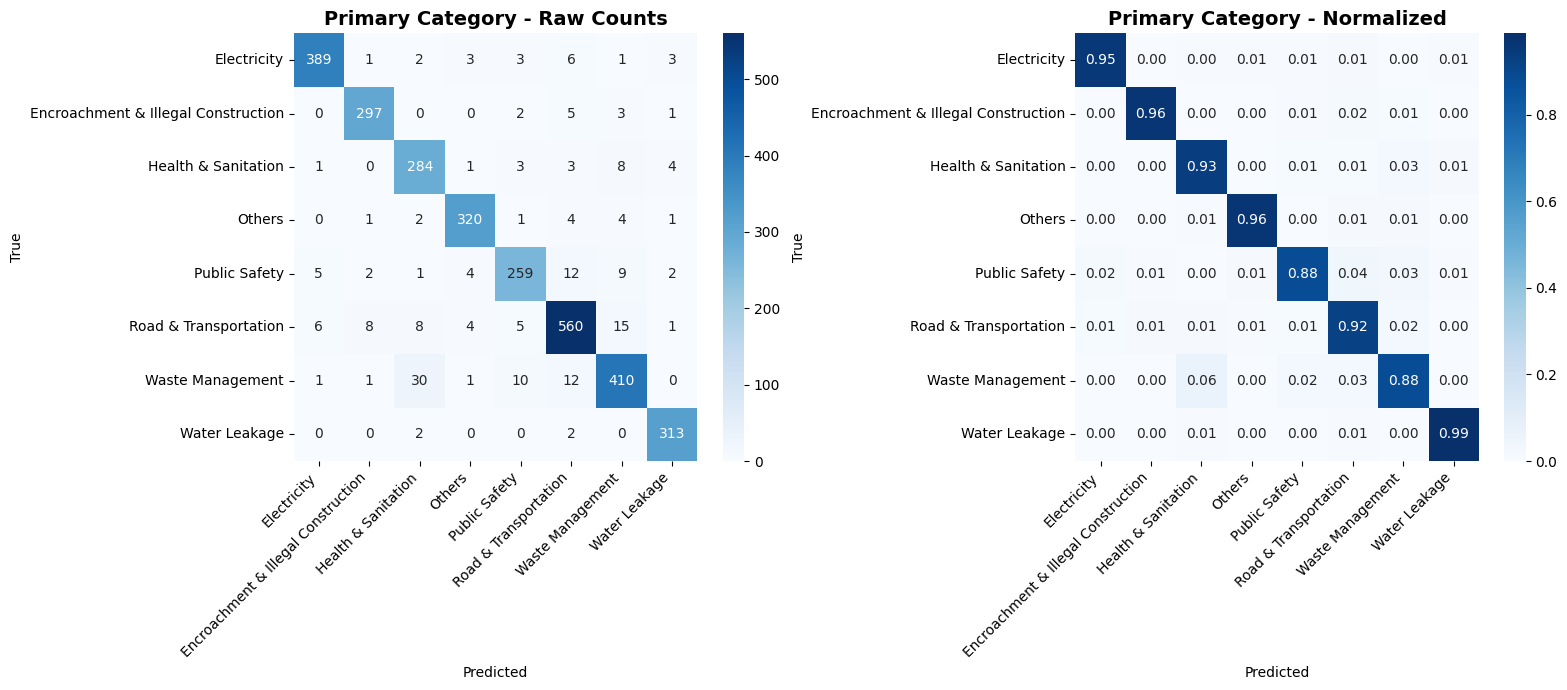

✅ Confusion matrix saved


In [13]:
# ============================================================================
# CELL 13: CONFUSION MATRIX
# ============================================================================

def plot_confusion_matrix_optimized(y_true, y_pred, class_names, title, save_path=None):
    cm = confusion_matrix(y_true, y_pred)
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    cm_normalized = np.nan_to_num(cm_normalized)
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=axes[0])
    axes[0].set_title(f'{title} - Raw Counts', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Predicted')
    axes[0].set_ylabel('True')
    axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
    
    sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=axes[1])
    axes[1].set_title(f'{title} - Normalized', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Predicted')
    axes[1].set_ylabel('True')
    axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
    
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

# Plot confusion matrix
class_names = preprocessor.le_primary.classes_
plot_confusion_matrix_optimized(
    test_labels, test_preds, class_names,
    'Primary Category',
    save_path=f"{Config.VISUALIZATION_DIR}/confusion_matrix_primary.png"
)

print(f"✅ Confusion matrix saved")

In [17]:
# ============================================================================
# CELL 16: COMPLETE SUMMARY REPORT
# ============================================================================

print("\n" + "="*80)
print(f"HIENBERT COMPLETE SUMMARY ({Config.BASE_MODEL.upper()})")
print("="*80)

print("\n1. DATASET STATISTICS:")
print(f"   Training: {len(train_df)}, Validation: {len(dev_df)}, Test: {len(test_df)}")
print(f"   Primary Categories: {len(preprocessor.le_primary.classes_)}")
print(f"   Subcategories: {len(preprocessor.le_subcat.classes_)}")
print(f"   Severity Levels: {len(preprocessor.le_severity.classes_)}")

print("\n2. MODEL STATISTICS:")
print(f"   Total Parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"   Hidden Size: {model.hidden_size}")
print(f"   Dropout: {Config.DROPOUT}")

print("\n3. TEST PERFORMANCE:")
for metric, value in test_metrics.items():
    if not isinstance(value, np.ndarray):
        print(f"   {metric}: {value:.4f}")

print(f"\n4. BEST VALIDATION:")
print(f"   F1: {best_val_f1:.4f}, Balanced Accuracy: {best_val_balanced_acc:.4f}")

print(f"\n5. TRAINING TIME:")
print(f"   Total: {total_time/60:.1f} minutes")

print("\n" + "="*80)
print("EXPERIMENT COMPLETED SUCCESSFULLY!")
print("="*80)


HIENBERT COMPLETE SUMMARY (XLM-ROBERTA)

1. DATASET STATISTICS:
   Training: 14165, Validation: 3035, Test: 3036
   Primary Categories: 8
   Subcategories: 24
   Severity Levels: 3

2. MODEL STATISTICS:
   Total Parameters: 278,661,155
   Hidden Size: 768
   Dropout: 0.3

3. TEST PERFORMANCE:
   accuracy: 0.9328
   balanced_accuracy: 0.9357
   f1_macro: 0.9342
   f1_weighted: 0.9328
   precision: 0.9332
   recall: 0.9328
   cohen_kappa: 0.9224
   mcc: 0.9225

4. BEST VALIDATION:
   F1: 0.9357, Balanced Accuracy: 0.9378

5. TRAINING TIME:
   Total: 90.0 minutes

EXPERIMENT COMPLETED SUCCESSFULLY!



STARTING LAYER-SCOPED ABLATION STUDY
Model Config from trained model:
  Hidden: 768
  Primary: 8, Subcat: 24, Severity: 3
  Encoder layers (self.base): 12
  Has Subcategory labels: True
  Has Severity labels: True

LAYER-SCOPED ABLATION STUDY (real submodules only)

Evaluating: BASELINE


  Primary Accuracy: 0.9318
  Primary F1: 0.9318
  Subcat Accuracy: 0.8650
  Severity Accuracy: 0.8956
  Overall Accuracy: 0.8975

Evaluating: SHARED_BYPASSED


  Primary Accuracy: 0.1047
  Primary F1: 0.0860
  Subcat Accuracy: 0.0375
  Severity Accuracy: 0.3047
  Overall Accuracy: 0.1490

Evaluating: GELU_REMOVED


  Primary Accuracy: 0.9335
  Primary F1: 0.9334
  Subcat Accuracy: 0.8623
  Severity Accuracy: 0.8959
  Overall Accuracy: 0.8972

Evaluating: SHARED_REINITIALIZED


  Primary Accuracy: 0.2042
  Primary F1: 0.1837
  Subcat Accuracy: 0.0310
  Severity Accuracy: 0.2708
  Overall Accuracy: 0.1686

Evaluating: FC_PRIMARY_REINITIALIZED


  Primary Accuracy: 0.0807
  Primary F1: 0.0826
  Subcat Accuracy: 0.8650
  Severity Accuracy: 0.8956
  Overall Accuracy: 0.6137

Evaluating: FC_SUBCAT_REINITIALIZED


... (2 outputs left out)

  Primary Accuracy: 0.9298
  Primary F1: 0.9298
  Subcat Accuracy: 0.8610
  Severity Accuracy: 0.8966
  Overall Accuracy: 0.8958

Evaluating: ENCODER_DEPTH_25PCT_L3


  Primary Accuracy: 0.1215
  Primary F1: 0.0969
  Subcat Accuracy: 0.0399
  Severity Accuracy: 0.3903
  Overall Accuracy: 0.1839

Evaluating: ENCODER_DEPTH_50PCT_L6


  Primary Accuracy: 0.1212
  Primary F1: 0.0968
  Subcat Accuracy: 0.0425
  Severity Accuracy: 0.3943
  Overall Accuracy: 0.1860

Evaluating: ENCODER_DEPTH_75PCT_L9


  Primary Accuracy: 0.1459
  Primary F1: 0.0831
  Subcat Accuracy: 0.0474
  Severity Accuracy: 0.3847
  Overall Accuracy: 0.1927
✓ Visualization saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\visualizations/layer_ablation_study.png


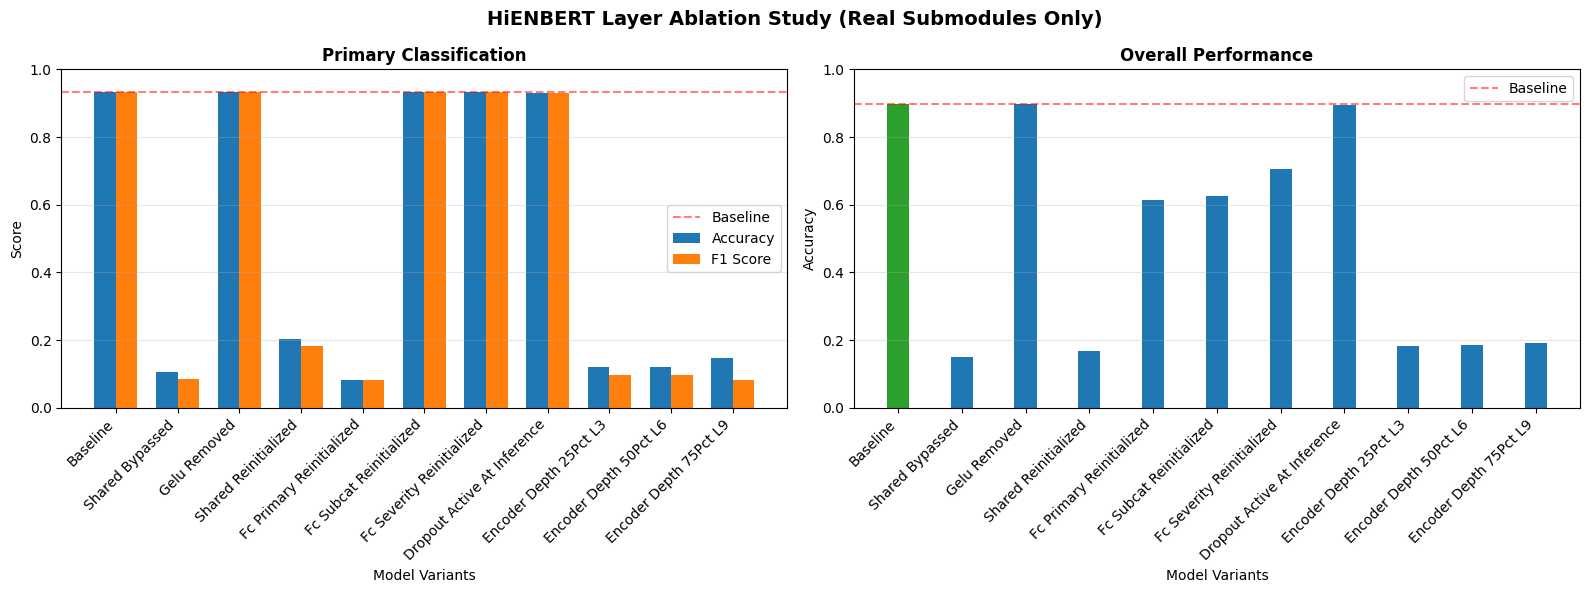


ABLATION STUDY REPORT

Baseline (Original Trained Model):
  Primary Accuracy: 0.9318
  Primary F1: 0.9318
  Severity Accuracy: 0.8956
  Overall Accuracy: 0.8975

--------------------------------------------------------------------------------
Ablation Results (Change from Baseline):
--------------------------------------------------------------------------------

SHARED BYPASSED:
  Primary Acc: 0.1047 (-0.8271) ✗ DEGRADED
  Overall Acc: 0.1490 (-0.7485)

GELU REMOVED:
  Primary Acc: 0.9335 (+0.0016) ✓ IMPROVED
  Overall Acc: 0.8972 (-0.0002)

SHARED REINITIALIZED:
  Primary Acc: 0.2042 (-0.7276) ✗ DEGRADED
  Overall Acc: 0.1686 (-0.7288)

FC PRIMARY REINITIALIZED:
  Primary Acc: 0.0807 (-0.8511) ✗ DEGRADED
  Overall Acc: 0.6137 (-0.2837)

FC SUBCAT REINITIALIZED:
  Primary Acc: 0.9318 (+0.0000) =
  Overall Acc: 0.6256 (-0.2718)

FC SEVERITY REINITIALIZED:
  Primary Acc: 0.9318 (+0.0000) =
  Overall Acc: 0.7051 (-0.1924)

DROPOUT ACTIVE AT INFERENCE:
  Primary Acc: 0.9298 (-0.0020) ✗ D

In [11]:
# ============================================================================
# CELL 15 (LAYER-SCOPED): ABLATION STUDY FOR OptimizedHiEnBERT
# ============================================================================
#
# Your trained model (Cell 6 / model-loading cell) is:
#
#   cls = base(...).last_hidden_state[:, 0, :]     <-- self.base: XLM-R encoder
#   x   = gelu(shared(cls))                        <-- self.shared: Linear(h,h)
#                                                       self.gelu:   GELU
#   x   = dropout(x)                                <-- self.dropout: Dropout(0.2)
#   return fc_primary(x), fc_subcat(x), fc_severity(x)   <-- 3 Linear heads
#
# This version only touches modules that actually exist in that graph:
# self.base, self.shared, self.gelu, self.dropout, self.fc_primary,
# self.fc_subcat, self.fc_severity. (An earlier draft tested substitute
# pooling strategies -- mean/max pooling, token shuffling -- that aren't
# part of the trained architecture at all; those are removed here.)
#
# Two distinct, legitimate senses of "ablation" are used, per layer:
#
#   BYPASS   -- skip the layer in the forward pass entirely.
#               Answers: "does this transformation step need to exist?"
#   KNOCKOUT -- keep the layer in the graph, same shape, but replace its
#               weights with a fresh random init (Xavier, matching your
#               model's own _init_weights).
#               Answers: "does the *trained content* of this layer matter,
#               or would any layer of that shape do?"
#
# Both are pure inference-time swaps -- no retraining, no .backward() calls
# -- so every number below is directly comparable to baseline.
#
# self.dropout deserves a special note: at eval() (which every variant runs
# under), nn.Dropout is a no-op by definition -- it literally cannot affect
# the output unless you deliberately force that one submodule back into
# train() mode while everything else stays in eval(). That's exactly what
# `dropout_active_at_inference` below does; without that trick, "ablating
# dropout" is guaranteed to equal baseline and isn't a real test.
#
# self.base is not knocked out or bypassed (it's the only source of
# information about the text -- there's nothing to compare it against).
# Instead it's probed by DEPTH: since it's a stack of transformer layers,
# `encoder_depth_*pct` variants read the CLS representation from an earlier
# layer instead of the final one, which is a genuine ablation of "how many
# of the encoder's own layers are actually needed."
# ============================================================================

import json
import os

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, f1_score
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm

# ============================================================================
# DATASET
# ============================================================================

class AblationDataset(Dataset):
    def __init__(self, data, tokenizer, max_length=128):
        self.data = data.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        text = str(row.get('text', ''))

        enc = self.tokenizer(
            text,
            truncation=True,
            padding='max_length',
            max_length=self.max_length,
            return_tensors='pt'
        )

        item = {
            'input_ids': enc['input_ids'].squeeze(),
            'attention_mask': enc['attention_mask'].squeeze(),
            'primary': torch.tensor(row['primary_label'], dtype=torch.long),
            'sentiment': torch.tensor(0.0, dtype=torch.float),
        }
        if 'subcat_label' in row:
            item['subcat'] = torch.tensor(row['subcat_label'], dtype=torch.long)
        if 'severity_label' in row:
            item['severity'] = torch.tensor(row['severity_label'], dtype=torch.long)

        return item


def _fresh_linear(in_features, out_features):
    """A new Linear layer, Xavier-initialized like OptimizedHiEnBERT._init_weights."""
    layer = nn.Linear(in_features, out_features)
    nn.init.xavier_uniform_(layer.weight)
    nn.init.zeros_(layer.bias)
    return layer


# ============================================================================
# ABLATION STUDY
# ============================================================================

class LayerAblationStudy:
    """
    Ablates only the real submodules of OptimizedHiEnBERT: base, shared,
    gelu, dropout, fc_primary, fc_subcat, fc_severity. All trained modules
    are reused by reference (no deepcopy -- nothing here calls .backward(),
    so sharing parameters across variants is safe and avoids duplicating a
    full XLM-R encoder per variant).
    """

    def __init__(self, trained_model, tokenizer, test_df, device):
        self.trained_model = trained_model
        self.tokenizer = tokenizer
        self.test_df = test_df
        self.device = device
        self.results = {}

        self.base = trained_model.base
        self.n_primary = trained_model.n_primary
        self.n_subcat = trained_model.n_subcat
        self.n_severity = trained_model.n_severity
        self.hidden_size = trained_model.hidden_size
        self.num_encoder_layers = getattr(self.base.config, 'num_hidden_layers', None)

        self.has_subcat = 'subcat_label' in test_df.columns
        self.has_severity = 'severity_label' in test_df.columns

        print("Model Config from trained model:")
        print(f"  Hidden: {self.hidden_size}")
        print(f"  Primary: {self.n_primary}, Subcat: {self.n_subcat}, Severity: {self.n_severity}")
        print(f"  Encoder layers (self.base): {self.num_encoder_layers}")
        print(f"  Has Subcategory labels: {self.has_subcat}")
        print(f"  Has Severity labels: {self.has_severity}")

        self._prepare_data()

    def _prepare_data(self):
        self.test_dataset = AblationDataset(self.test_df, self.tokenizer)
        self.test_loader = DataLoader(
            self.test_dataset, batch_size=64, shuffle=False, num_workers=0
        )

    def evaluate_model(self, model, description="", force_dropout_train=False):
        """
        Evaluate a variant. force_dropout_train=True keeps every submodule
        in eval() EXCEPT model.dropout, which is pushed back into train()
        so it actually applies at inference (see module docstring above).
        """
        model.eval()
        if force_dropout_train:
            model.dropout.train()

        preds = {'primary': [], 'subcat': [], 'severity': []}
        labels = {'primary': [], 'subcat': [], 'severity': []}

        with torch.no_grad():
            for batch in tqdm(self.test_loader, desc=f'Evaluating {description}', leave=False):
                input_ids = batch['input_ids'].to(self.device)
                attention_mask = batch['attention_mask'].to(self.device)
                sentiment = batch['sentiment'].to(self.device)

                p1, p2, p3 = model(input_ids, attention_mask, sentiment)

                preds['primary'].extend(torch.argmax(p1, dim=1).cpu().numpy())
                labels['primary'].extend(batch['primary'].cpu().numpy())

                if self.has_subcat and 'subcat' in batch:
                    preds['subcat'].extend(torch.argmax(p2, dim=1).cpu().numpy())
                    labels['subcat'].extend(batch['subcat'].cpu().numpy())

                if self.has_severity and 'severity' in batch:
                    preds['severity'].extend(torch.argmax(p3, dim=1).cpu().numpy())
                    labels['severity'].extend(batch['severity'].cpu().numpy())

        metrics = {
            'primary_accuracy': accuracy_score(labels['primary'], preds['primary']),
            'primary_f1_weighted': f1_score(
                labels['primary'], preds['primary'], average='weighted', zero_division=0
            ),
        }
        task_accs = [metrics['primary_accuracy']]

        if labels['subcat']:
            metrics['subcat_accuracy'] = accuracy_score(labels['subcat'], preds['subcat'])
            metrics['subcat_f1_weighted'] = f1_score(
                labels['subcat'], preds['subcat'], average='weighted', zero_division=0
            )
            task_accs.append(metrics['subcat_accuracy'])

        if labels['severity']:
            metrics['severity_accuracy'] = accuracy_score(labels['severity'], preds['severity'])
            metrics['severity_f1_weighted'] = f1_score(
                labels['severity'], preds['severity'], average='weighted', zero_division=0
            )
            task_accs.append(metrics['severity_accuracy'])

        metrics['overall_accuracy'] = float(np.mean(task_accs))
        return metrics

    # ========================================================================
    # BYPASS VARIANTS -- skip a real layer's transformation entirely
    # ========================================================================

    def create_variant_shared_bypassed(self):
        """Skip self.shared + self.gelu; raw CLS goes straight into the trained heads."""
        base = self.base
        dropout = self.trained_model.dropout
        fc_primary = self.trained_model.fc_primary
        fc_subcat = self.trained_model.fc_subcat
        fc_severity = self.trained_model.fc_severity

        class SharedBypassed(nn.Module):
            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(input_ids=input_ids, attention_mask=attention_mask)
                cls = outputs.last_hidden_state[:, 0, :]
                x = dropout(cls)
                return fc_primary(x), fc_subcat(x), fc_severity(x)

        return SharedBypassed()

    def create_variant_gelu_removed(self):
        """Keep the trained self.shared Linear, drop the self.gelu nonlinearity."""
        base = self.base
        shared = self.trained_model.shared
        dropout = self.trained_model.dropout
        fc_primary = self.trained_model.fc_primary
        fc_subcat = self.trained_model.fc_subcat
        fc_severity = self.trained_model.fc_severity

        class GeluRemoved(nn.Module):
            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(input_ids=input_ids, attention_mask=attention_mask)
                cls = outputs.last_hidden_state[:, 0, :]
                x = shared(cls)  # linear only, no GELU
                x = dropout(x)
                return fc_primary(x), fc_subcat(x), fc_severity(x)

        return GeluRemoved()

    # ========================================================================
    # KNOCKOUT VARIANTS -- keep the layer, randomize its trained weights
    # ========================================================================

    def create_variant_shared_reinitialized(self):
        """self.shared's trained weights replaced with a fresh random Linear."""
        base = self.base
        gelu = self.trained_model.gelu
        dropout = self.trained_model.dropout
        fc_primary = self.trained_model.fc_primary
        fc_subcat = self.trained_model.fc_subcat
        fc_severity = self.trained_model.fc_severity
        new_shared = _fresh_linear(self.hidden_size, self.hidden_size)

        class SharedReinitialized(nn.Module):
            def __init__(self):
                super().__init__()
                self.shared = new_shared  # registered submodule so .to(device) moves it

            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(input_ids=input_ids, attention_mask=attention_mask)
                cls = outputs.last_hidden_state[:, 0, :]
                x = gelu(self.shared(cls))
                x = dropout(x)
                return fc_primary(x), fc_subcat(x), fc_severity(x)

        return SharedReinitialized()

    def _create_head_reinitialized(self, head_name, out_features):
        """Generic knockout for one of the three trained classification heads."""
        base = self.base
        shared = self.trained_model.shared
        gelu = self.trained_model.gelu
        dropout = self.trained_model.dropout
        trained_fc_primary = self.trained_model.fc_primary
        trained_fc_subcat = self.trained_model.fc_subcat
        trained_fc_severity = self.trained_model.fc_severity
        new_head = _fresh_linear(self.hidden_size, out_features)

        class HeadReinitialized(nn.Module):
            def __init__(self):
                super().__init__()
                self.reinit_head = new_head  # registered submodule so .to(device) moves it

            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(input_ids=input_ids, attention_mask=attention_mask)
                cls = outputs.last_hidden_state[:, 0, :]
                x = gelu(shared(cls))
                x = dropout(x)
                p1 = self.reinit_head(x) if head_name == 'fc_primary' else trained_fc_primary(x)
                p2 = self.reinit_head(x) if head_name == 'fc_subcat' else trained_fc_subcat(x)
                p3 = self.reinit_head(x) if head_name == 'fc_severity' else trained_fc_severity(x)
                return p1, p2, p3

        return HeadReinitialized()

    def create_variant_fc_primary_reinitialized(self):
        """Trained fc_primary head replaced with random weights (fc_subcat/severity untouched)."""
        return self._create_head_reinitialized('fc_primary', self.n_primary)

    def create_variant_fc_subcat_reinitialized(self):
        """Trained fc_subcat head replaced with random weights (fc_primary/severity untouched)."""
        return self._create_head_reinitialized('fc_subcat', self.n_subcat)

    def create_variant_fc_severity_reinitialized(self):
        """Trained fc_severity head replaced with random weights (fc_primary/subcat untouched)."""
        return self._create_head_reinitialized('fc_severity', self.n_severity)

    # ========================================================================
    # DROPOUT -- the only way to actually exercise self.dropout at eval time
    # ========================================================================

    def create_variant_dropout_active(self):
        """
        Same trained self.dropout module (p=0.2), but forced into train()
        mode via evaluate_model(force_dropout_train=True) so it's actually
        stochastic instead of a no-op. Note: this makes the forward pass
        non-deterministic, so re-running it will give slightly different
        numbers each time -- that's expected, not a bug.
        """
        base = self.base
        shared = self.trained_model.shared
        gelu = self.trained_model.gelu
        dropout = self.trained_model.dropout
        fc_primary = self.trained_model.fc_primary
        fc_subcat = self.trained_model.fc_subcat
        fc_severity = self.trained_model.fc_severity

        class DropoutActive(nn.Module):
            def __init__(self):
                super().__init__()
                self.dropout = dropout  # exposed as self.dropout so evaluate_model can .train() it

            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(input_ids=input_ids, attention_mask=attention_mask)
                cls = outputs.last_hidden_state[:, 0, :]
                x = gelu(shared(cls))
                x = self.dropout(x)
                return fc_primary(x), fc_subcat(x), fc_severity(x)

        return DropoutActive()

    # ========================================================================
    # ENCODER DEPTH -- probing self.base's own stacked layers
    # ========================================================================

    def create_variant_encoder_depth(self, layer_idx):
        """
        Use the CLS token from an intermediate encoder layer (layer_idx,
        via output_hidden_states) instead of the final layer, through the
        same trained shared -> gelu -> dropout -> heads pipeline. Those
        downstream layers were trained on the FINAL layer's representation,
        so this is deliberately out-of-distribution -- it measures how much
        representational work the later encoder layers are doing.
        """
        base = self.base
        shared = self.trained_model.shared
        gelu = self.trained_model.gelu
        dropout = self.trained_model.dropout
        fc_primary = self.trained_model.fc_primary
        fc_subcat = self.trained_model.fc_subcat
        fc_severity = self.trained_model.fc_severity

        class EncoderDepthProbe(nn.Module):
            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    output_hidden_states=True,
                )
                cls = outputs.hidden_states[layer_idx][:, 0, :]
                x = gelu(shared(cls))
                x = dropout(x)
                return fc_primary(x), fc_subcat(x), fc_severity(x)

        return EncoderDepthProbe()

    # ========================================================================
    # RUN
    # ========================================================================

    def run_study(self):
        print("\n" + "=" * 80)
        print("LAYER-SCOPED ABLATION STUDY (real submodules only)")
        print("=" * 80)

        variants = {
            'baseline': (self.trained_model, {}),
            'shared_bypassed': (self.create_variant_shared_bypassed(), {}),
            'gelu_removed': (self.create_variant_gelu_removed(), {}),
            'shared_reinitialized': (self.create_variant_shared_reinitialized(), {}),
            'fc_primary_reinitialized': (self.create_variant_fc_primary_reinitialized(), {}),
            'fc_subcat_reinitialized': (self.create_variant_fc_subcat_reinitialized(), {}),
            'fc_severity_reinitialized': (self.create_variant_fc_severity_reinitialized(), {}),
            'dropout_active_at_inference': (
                self.create_variant_dropout_active(), {'force_dropout_train': True}
            ),
        }

        # Encoder-depth probes: 25% / 50% / 75% through self.base's own layers.
        # (100% depth == last_hidden_state == identical to baseline, so it's
        # not included as a separate variant.)
        if self.num_encoder_layers:
            for frac in (0.25, 0.5, 0.75):
                layer_idx = max(1, round(self.num_encoder_layers * frac))
                name = f'encoder_depth_{int(frac * 100)}pct_L{layer_idx}'
                variants[name] = (self.create_variant_encoder_depth(layer_idx), {})
        else:
            print("  (Skipping encoder-depth probes: base_model.config.num_hidden_layers not found)")

        for name, (variant_model, eval_kwargs) in variants.items():
            print(f"\n{'=' * 60}\nEvaluating: {name.upper()}\n{'=' * 60}")
            try:
                variant_model = variant_model.to(self.device)

                metrics = self.evaluate_model(variant_model, name, **eval_kwargs)
                self.results[name] = metrics

                print(f"  Primary Accuracy: {metrics['primary_accuracy']:.4f}")
                print(f"  Primary F1: {metrics['primary_f1_weighted']:.4f}")
                if 'subcat_accuracy' in metrics:
                    print(f"  Subcat Accuracy: {metrics['subcat_accuracy']:.4f}")
                if 'severity_accuracy' in metrics:
                    print(f"  Severity Accuracy: {metrics['severity_accuracy']:.4f}")
                print(f"  Overall Accuracy: {metrics['overall_accuracy']:.4f}")

                if name != 'baseline':
                    del variant_model
                    if torch.cuda.is_available():
                        torch.cuda.empty_cache()

            except Exception as e:
                print(f"  \u2717 Failed: {e}")
                import traceback
                traceback.print_exc()

        return self.results

    # ========================================================================
    # VISUALIZATION
    # ========================================================================

    def visualize_results(self, save_path=None):
        if not self.results:
            print("No results to visualize")
            return

        variants = list(self.results.keys())
        fig, axes = plt.subplots(1, 2, figsize=(16, 6))

        primary_acc = [self.results[v]['primary_accuracy'] for v in variants]
        primary_f1 = [self.results[v]['primary_f1_weighted'] for v in variants]

        x = np.arange(len(variants))
        width = 0.35

        axes[0].bar(x - width / 2, primary_acc, width, label='Accuracy', color='#1f77b4')
        axes[0].bar(x + width / 2, primary_f1, width, label='F1 Score', color='#ff7f0e')
        axes[0].axhline(
            y=self.results['baseline']['primary_accuracy'],
            color='red', linestyle='--', alpha=0.5, label='Baseline'
        )
        axes[0].set_xlabel('Model Variants')
        axes[0].set_ylabel('Score')
        axes[0].set_title('Primary Classification', fontsize=12, fontweight='bold')
        axes[0].set_xticks(x)
        axes[0].set_xticklabels([v.replace('_', ' ').title() for v in variants], rotation=45, ha='right')
        axes[0].legend()
        axes[0].grid(True, alpha=0.3, axis='y')
        axes[0].set_ylim(0, 1)

        overall_acc = [self.results[v]['overall_accuracy'] for v in variants]
        colors = ['#2ca02c' if v == 'baseline' else '#1f77b4' for v in variants]
        axes[1].bar(x, overall_acc, width, color=colors)
        axes[1].axhline(
            y=self.results['baseline']['overall_accuracy'],
            color='red', linestyle='--', alpha=0.5, label='Baseline'
        )
        axes[1].set_xlabel('Model Variants')
        axes[1].set_ylabel('Accuracy')
        axes[1].set_title('Overall Performance', fontsize=12, fontweight='bold')
        axes[1].set_xticks(x)
        axes[1].set_xticklabels([v.replace('_', ' ').title() for v in variants], rotation=45, ha='right')
        axes[1].legend()
        axes[1].grid(True, alpha=0.3, axis='y')
        axes[1].set_ylim(0, 1)

        plt.suptitle('HiENBERT Layer Ablation Study (Real Submodules Only)', fontsize=14, fontweight='bold')
        plt.tight_layout()

        if save_path:
            os.makedirs(os.path.dirname(save_path), exist_ok=True)
            plt.savefig(save_path, dpi=300, bbox_inches='tight')
            print(f"\u2713 Visualization saved to: {save_path}")

        plt.show()
        plt.close()

    def generate_report(self):
        print("\n" + "=" * 80)
        print("ABLATION STUDY REPORT")
        print("=" * 80)

        if not self.results:
            print("No results available!")
            return

        baseline = self.results.get('baseline', {})
        print("\nBaseline (Original Trained Model):")
        print(f"  Primary Accuracy: {baseline.get('primary_accuracy', 0):.4f}")
        print(f"  Primary F1: {baseline.get('primary_f1_weighted', 0):.4f}")
        if 'severity_accuracy' in baseline:
            print(f"  Severity Accuracy: {baseline.get('severity_accuracy', 0):.4f}")
        print(f"  Overall Accuracy: {baseline.get('overall_accuracy', 0):.4f}")

        print("\n" + "-" * 80)
        print("Ablation Results (Change from Baseline):")
        print("-" * 80)

        for name, metrics in self.results.items():
            if name == 'baseline':
                continue

            primary_change = metrics.get('primary_accuracy', 0) - baseline.get('primary_accuracy', 0)
            overall_change = metrics.get('overall_accuracy', 0) - baseline.get('overall_accuracy', 0)

            if primary_change > 1e-9:
                status = "\u2713 IMPROVED"
            elif primary_change < -1e-9:
                status = "\u2717 DEGRADED"
            else:
                status = "="

            print(f"\n{name.upper().replace('_', ' ')}:")
            print(f"  Primary Acc: {metrics.get('primary_accuracy', 0):.4f} ({primary_change:+.4f}) {status}")
            print(f"  Overall Acc: {metrics.get('overall_accuracy', 0):.4f} ({overall_change:+.4f})")


# ============================================================================
# RUN
# ============================================================================

print("\n" + "=" * 80)
print("STARTING LAYER-SCOPED ABLATION STUDY")
print("=" * 80)

try:
    ablation = LayerAblationStudy(
        trained_model=model,
        tokenizer=tokenizer,
        test_df=test_df,
        device=Config.DEVICE
    )

    ablation_results = ablation.run_study()

    os.makedirs(Config.VISUALIZATION_DIR, exist_ok=True)
    ablation.visualize_results(
        save_path=f"{Config.VISUALIZATION_DIR}/layer_ablation_study.png"
    )

    ablation.generate_report()

    os.makedirs(Config.RESULTS_DIR, exist_ok=True)
    clean_results = {
        k: {kk: (float(vv) if isinstance(vv, (np.float32, np.float64)) else vv) for kk, vv in v.items()}
        for k, v in ablation_results.items()
    }
    with open(f"{Config.RESULTS_DIR}/layer_ablation_results.json", "w") as f:
        json.dump(clean_results, f, indent=4)

    print(f"\n\u2713 Results saved to: {Config.RESULTS_DIR}/layer_ablation_results.json")
    print("\n\u2713 Ablation study completed successfully!")

except Exception as e:
    print(f"Error during ablation study: {e}")
    import traceback
    traceback.print_exc()

In [19]:
# ============================================================================
# CELL 20: COMPLETE SUMMARY REPORT
# ============================================================================

def generate_summary_report():
    """Generate comprehensive summary report"""
    
    print("\n" + "="*80)
    print(f"HIENBERT COMPREHENSIVE SUMMARY REPORT ({Config.BASE_MODEL.upper()} Base)")
    print("="*80)
    
    # 1. Dataset Statistics
    print("\n1. DATASET STATISTICS:")
    print(f"   Training samples: {len(train_df)}")
    print(f"   Validation samples: {len(dev_df)}")
    print(f"   Test samples: {len(test_df)}")
    print(f"   Primary categories: {len(preprocessor.le_primary.classes_)}")
    print(f"   Subcategories: {len(preprocessor.le_subcat.classes_)}")
    print(f"   Severity levels: {len(preprocessor.le_severity.classes_)}")
    
    # 2. Model Architecture
    print("\n2. MODEL ARCHITECTURE:")
    print(f"   Base Model: {Config.BASE_MODEL.upper()}")
    print(f"   Model Path: {get_model_path()}")
    print(f"   Hidden Size: {model.hidden_size}")
    print(f"   Total Parameters: {sum(p.numel() for p in model.parameters()):,}")
    print(f"   Dropout Rate: {Config.DROPOUT}")
    print(f"   Max Sequence Length: {Config.MAX_LENGTH}")
    
    # # 3. Imbalance Handling
    # print("\n3. IMBALANCE HANDLING:")
    # print(f"   Class Weights: {Config.USE_CLASS_WEIGHTS}")
    # print(f"   Focal Loss: {Config.USE_FOCAL_LOSS}")
    # if Config.USE_FOCAL_LOSS:
    #     print(f"   Focal Alpha: {Config.FOCAL_ALPHA}")
    #     print(f"   Focal Gamma: {Config.FOCAL_GAMMA}")
    # print(f"   Weighted Sampler: {Config.USE_WEIGHTED_SAMPLER}")
    
    # 4. Training Details
    print("\n4. TRAINING DETAILS:")
    print(f"   Epochs: {Config.EPOCHS}")
    print(f"   Batch Size: {Config.BATCH_SIZE}")
    print(f"   Learning Rate: {Config.LEARNING_RATE}")
    print(f"   Weight Decay: {Config.WEIGHT_DECAY}")
    print(f"   Mixed Precision: {Config.USE_AMP}")
    
    # 5. Test Performance
    print("\n5. TEST SET PERFORMANCE:")
    for metric, value in test_metrics.items():
        if isinstance(value, (int, float)) and metric != 'confidences':
            print(f"   {metric}: {value:.4f}")
    
    # 6. Best Validation Performance
    print("\n6. BEST VALIDATION PERFORMANCE:")
    print(f"   Best Validation F1: {best_val_f1:.4f}")
    print(f"   Best Validation Balanced Accuracy: {best_val_balanced_acc:.4f}")
    
    # 7. Training History
    print("\n7. TRAINING HISTORY:")
    print(f"   Final Train Loss: {train_history[-1]['loss']:.4f}")
    print(f"   Final Train Accuracy: {train_history[-1]['acc']:.4f}")
    print(f"   Final Train Balanced Accuracy: {train_history[-1]['balanced_acc']:.4f}")
    
    # 8. Severity Distribution
    print("\n8. SEVERITY DISTRIBUTION (Training):")
    severity_dist = train_df['severity'].value_counts()
    severity_pct = train_df['severity'].value_counts(normalize=True) * 100
    for severity in ['LOW', 'MEDIUM', 'HIGH']:
        print(f"   {severity}: {severity_dist.get(severity, 0)} ({severity_pct.get(severity, 0):.1f}%)")
    
    # 9. Saved Files
    print("\n9. SAVED FILES:")
    print(f"   Best Model: {Config.MODEL_DIR}/best_hienbert_model.pt")
    print(f"   Final Model: {Config.MODEL_DIR}/hienbert_model.pt")
    print(f"   Encoders: {Config.MODEL_DIR}/le_*.pkl")
    print(f"   Test Results: {Config.RESULTS_DIR}/test_results.json")
    print(f"   Comparison Table: {Config.RESULTS_DIR}/model_comparison.csv")
    print(f"   Visualizations: {Config.VISUALIZATION_DIR}/")
    
    print("\n" + "="*80)
    print("END OF SUMMARY REPORT")
    print("="*80)
    
    # Save report to file
    with open(f"{Config.RESULTS_DIR}/summary_report.txt", 'w') as f:
        f.write(f"HIENBERT COMPREHENSIVE SUMMARY REPORT ({Config.BASE_MODEL.upper()} Base)\n")
        f.write("="*80 + "\n\n")
        # Write all the above information to file
        # ... (similar content as printed)

# Generate summary report
generate_summary_report()

print(f"\n✅ All results saved to: {Config.BASE_DIR}")
print(f"📁 Results directory: {Config.RESULTS_DIR}")
print(f"📁 Visualizations directory: {Config.VISUALIZATION_DIR}")
print(f"📁 Models directory: {Config.MODEL_DIR}")
print(f"\n{'='*80}")
print("EXPERIMENT COMPLETED SUCCESSFULLY!")
print(f"Base Model: {Config.BASE_MODEL.upper()}")
print("="*80)


HIENBERT COMPREHENSIVE SUMMARY REPORT (XLM-ROBERTA Base)

1. DATASET STATISTICS:
   Training samples: 14165
   Validation samples: 3035
   Test samples: 3036
   Primary categories: 8
   Subcategories: 24
   Severity levels: 3

2. MODEL ARCHITECTURE:
   Base Model: XLM-ROBERTA
   Model Path: xlm-roberta-base
   Hidden Size: 768
   Total Parameters: 278,661,155
   Dropout Rate: 0.3
   Max Sequence Length: 128

4. TRAINING DETAILS:
   Epochs: 15
   Batch Size: 32
   Learning Rate: 2e-05
   Weight Decay: 0.01
   Mixed Precision: True

5. TEST SET PERFORMANCE:
   accuracy: 0.9328
   balanced_accuracy: 0.9357
   f1_macro: 0.9342
   f1_weighted: 0.9328
   precision: 0.9332
   recall: 0.9328
   cohen_kappa: 0.9224
   mcc: 0.9225

6. BEST VALIDATION PERFORMANCE:
   Best Validation F1: 0.9357
   Best Validation Balanced Accuracy: 0.9378

7. TRAINING HISTORY:
   Final Train Loss: 0.0912
   Final Train Accuracy: 0.9954
   Final Train Balanced Accuracy: 0.9954

8. SEVERITY DISTRIBUTION (Training):

In [23]:
# ============================================================================
# COMPLETE LANGUAGE-WISE PERFORMANCE ANALYSIS WITH ALL METRICS - FIXED
# ============================================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix, balanced_accuracy_score,
    cohen_kappa_score, matthews_corrcoef
)


# ============================================================================
# DATASET CLASSES
# ============================================================================

class LanguageWiseDataset(Dataset):
    """
    Dataset that uses a specific language column for evaluation.
    """
    def __init__(self, df, tokenizer, text_column, max_length=128):
        self.texts = df[text_column].fillna('').astype(str).tolist()
        self.primary = torch.tensor(df["primary_label"].values, dtype=torch.long)
        self.subcat = torch.tensor(df["subcat_label"].values, dtype=torch.long)
        self.severity = torch.tensor(df["severity_label"].values, dtype=torch.long)
        self.tokenizer = tokenizer
        self.max_length = max_length
    
    def __len__(self):
        return len(self.texts)
    
    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )
        return {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "primary": self.primary[idx],
            "subcat": self.subcat[idx],
            "severity": self.severity[idx],
            "sentiment": torch.tensor(0.0, dtype=torch.float)
        }


class PreTokenizedEvalDataset(Dataset):
    """
    Pre-tokenized dataset for faster evaluation.
    """
    def __init__(self, df, tokenizer, max_length=128):
        print("Pre-tokenizing dataset for evaluation...")
        self.primary = torch.tensor(df["primary_label"].values, dtype=torch.long)
        self.subcat = torch.tensor(df["subcat_label"].values, dtype=torch.long)
        self.severity = torch.tensor(df["severity_label"].values, dtype=torch.long)
        
        texts = df["text"].astype(str).tolist()
        encodings = tokenizer(
            texts,
            truncation=True,
            padding="max_length",
            max_length=max_length,
            return_tensors="pt"
        )
        self.input_ids = encodings["input_ids"]
        self.attention_mask = encodings["attention_mask"]
        self.sentiment = torch.zeros(len(df), dtype=torch.float)
        print(f"✅ Pre-tokenized {len(df)} samples")
    
    def __len__(self):
        return len(self.primary)
    
    def __getitem__(self, idx):
        return {
            "input_ids": self.input_ids[idx],
            "attention_mask": self.attention_mask[idx],
            "primary": self.primary[idx],
            "subcat": self.subcat[idx],
            "severity": self.severity[idx],
            "sentiment": self.sentiment[idx]
        }


# ============================================================================
# EVALUATION FUNCTIONS
# ============================================================================

def evaluate_task(model, dataloader, device, task='primary', return_predictions=False):
    """
    Evaluate model for a specific task.
    """
    model.eval()
    
    task_map = {'primary': 0, 'subcat': 1, 'severity': 2}
    output_idx = task_map[task]
    
    all_preds, all_labels, all_confidences = [], [], []
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc=f'Evaluating {task}', leave=False):
            input_ids = batch['input_ids'].to(device, non_blocking=True)
            attention_mask = batch['attention_mask'].to(device, non_blocking=True)
            sentiment = batch['sentiment'].to(device, non_blocking=True)
            
            p1, p2, p3 = model(input_ids, attention_mask, sentiment)
            outputs = [p1, p2, p3]
            
            logits = outputs[output_idx]
            probs = torch.softmax(logits, dim=1)
            preds = torch.argmax(logits, dim=1)
            
            if task == 'primary':
                labels = batch['primary']
            elif task == 'subcat':
                labels = batch['subcat']
            else:
                labels = batch['severity']
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_confidences.extend(probs.max(dim=1)[0].cpu().numpy())
    
    metrics = {
        'accuracy': accuracy_score(all_labels, all_preds),
        'balanced_accuracy': balanced_accuracy_score(all_labels, all_preds),
        'f1_macro': f1_score(all_labels, all_preds, average='macro', zero_division=0),
        'f1_weighted': f1_score(all_labels, all_preds, average='weighted', zero_division=0),
        'precision': precision_score(all_labels, all_preds, average='weighted', zero_division=0),
        'recall': recall_score(all_labels, all_preds, average='weighted', zero_division=0),
        'cohen_kappa': cohen_kappa_score(all_labels, all_preds),
        'mcc': matthews_corrcoef(all_labels, all_preds),
        'support': len(all_labels),
        'confidences': np.array(all_confidences)
    }
    
    if return_predictions:
        return metrics, all_preds, all_labels
    return metrics


# ============================================================================
# LANGUAGE-WISE ANALYSIS
# ============================================================================

def analyze_language_performance(model, test_df, tokenizer, device, 
                                  class_names=None, batch_size=32, max_length=128):
    """
    Analyze model performance by language and by task.
    """
    print("\n" + "="*80)
    print("COMPREHENSIVE LANGUAGE-WISE AND CATEGORY-WISE ANALYSIS")
    print("="*80)
    
    language_columns = {
        'English': 'text_en',
        'Hindi': 'Hindi',
        'Hinglish': 'Hinglish'
    }
    
    results = {
        'language_performance': {},
        'overall_language_performance': {},
        'task_performance': {},
        'predictions': {}
    }
    
    # ========================================================================
    # 1. LANGUAGE-WISE PERFORMANCE
    # ========================================================================
    
    print("\n" + "-"*80)
    print("LANGUAGE-WISE PERFORMANCE")
    print("-"*80)
    
    for lang_name, col_name in language_columns.items():
        print(f"\n📊 Evaluating: {lang_name}")
        
        lang_df = test_df[
            test_df[col_name].notna() & 
            (test_df[col_name].astype(str).str.strip() != '')
        ].copy()
        
        if len(lang_df) == 0:
            print(f"   ⚠️ No samples found for {lang_name}")
            results['language_performance'][lang_name] = {'error': 'No samples'}
            continue
        
        dataset = LanguageWiseDataset(lang_df, tokenizer, col_name, max_length)
        loader = DataLoader(
            dataset,
            batch_size=batch_size,
            shuffle=False,
            num_workers=0,
            pin_memory=True
        )
        
        lang_metrics = {}
        for task in ['primary', 'subcat', 'severity']:
            metrics = evaluate_task(model, loader, device, task=task)
            lang_metrics[task] = metrics
        
        results['language_performance'][lang_name] = lang_metrics
        
        print(f"   Samples: {len(lang_df)}")
        print(f"   Primary  - Acc: {lang_metrics['primary']['accuracy']:.4f}, F1-W: {lang_metrics['primary']['f1_weighted']:.4f}, Kappa: {lang_metrics['primary']['cohen_kappa']:.4f}")
        print(f"   Subcat   - Acc: {lang_metrics['subcat']['accuracy']:.4f}, F1-W: {lang_metrics['subcat']['f1_weighted']:.4f}, Kappa: {lang_metrics['subcat']['cohen_kappa']:.4f}")
        print(f"   Severity - Acc: {lang_metrics['severity']['accuracy']:.4f}, F1-W: {lang_metrics['severity']['f1_weighted']:.4f}, Kappa: {lang_metrics['severity']['cohen_kappa']:.4f}")
    
    # ========================================================================
    # 2. OVERALL LANGUAGE PERFORMANCE (Average Across All Tasks)
    # ========================================================================
    
    print("\n" + "-"*80)
    print("OVERALL LANGUAGE PERFORMANCE (Average Across All Tasks)")
    print("-"*80)
    
    for lang_name, metrics in results['language_performance'].items():
        if 'error' not in metrics:
            # Calculate average across tasks
            avg_metrics = {}
            metric_keys = ['accuracy', 'balanced_accuracy', 'f1_macro', 'f1_weighted', 
                          'precision', 'recall', 'cohen_kappa', 'mcc']
            
            for key in metric_keys:
                values = [metrics[task][key] for task in ['primary', 'subcat', 'severity']]
                avg_metrics[key] = np.mean(values)
            
            avg_metrics['support'] = metrics['primary']['support']
            results['overall_language_performance'][lang_name] = avg_metrics
    
    # Print Overall Language Performance Table
    print("\n📊 OVERALL LANGUAGE PERFORMANCE (Average of Primary + Subcat + Severity):")
    print("=" * 130)
    print(f"{'Language':<12} {'Accuracy':<12} {'Bal Acc':<12} {'F1-Macro':<12} {'F1-Weighted':<14} {'Precision':<12} {'Recall':<12} {'Kappa':<12} {'MCC':<12}")
    print("=" * 130)
    for lang, m in results['overall_language_performance'].items():
        print(f"{lang:<12} {m['accuracy']:.4f}     {m['balanced_accuracy']:.4f}     {m['f1_macro']:.4f}     {m['f1_weighted']:.4f}       {m['precision']:.4f}     {m['recall']:.4f}     {m['cohen_kappa']:.4f}     {m['mcc']:.4f}")
    
    # ========================================================================
    # 3. OVERALL TASK PERFORMANCE (using combined text)
    # ========================================================================
    
    print("\n" + "-"*80)
    print("OVERALL TASK PERFORMANCE (Combined Text)")
    print("-"*80)
    
    eval_dataset = PreTokenizedEvalDataset(test_df, tokenizer, max_length)
    eval_loader = DataLoader(
        eval_dataset,
        batch_size=batch_size * 2,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )
    
    for task in ['primary', 'subcat', 'severity']:
        metrics, preds, labels = evaluate_task(
            model, eval_loader, device, task=task, return_predictions=True
        )
        results['task_performance'][task] = metrics
        results['predictions'][task] = {'preds': preds, 'labels': labels}
    
    print("\nOverall Performance:")
    print("-" * 130)
    print(f"{'Task':<12} {'Accuracy':<12} {'Bal Acc':<12} {'F1-Macro':<12} {'F1-Weighted':<14} {'Precision':<12} {'Recall':<12} {'Kappa':<12} {'MCC':<12}")
    print("-" * 130)
    for task in ['primary', 'subcat', 'severity']:
        m = results['task_performance'][task]
        print(f"{task.upper():<12} {m['accuracy']:.4f}     {m['balanced_accuracy']:.4f}     {m['f1_macro']:.4f}     {m['f1_weighted']:.4f}       {m['precision']:.4f}     {m['recall']:.4f}     {m['cohen_kappa']:.4f}     {m['mcc']:.4f}")
    
    # ========================================================================
    # 4. CLASS-WISE PERFORMANCE (Primary) - FIXED
    # ========================================================================
    
    print("\n" + "-"*80)
    print("CLASS-WISE PERFORMANCE (Primary Categories)")
    print("-"*80)
    
    if class_names is not None:
        primary_preds = results['predictions']['primary']['preds']
        primary_labels = results['predictions']['primary']['labels']
        
        # Get classification report
        report = classification_report(
            primary_labels, primary_preds,
            target_names=class_names,
            output_dict=True,
            zero_division=0
        )
        
        print("\nPer-Class Performance:")
        print("-" * 80)
        print(f"{'Category':<35} {'Precision':<12} {'Recall':<12} {'F1-Score':<12} {'Support':<10}")
        print("-" * 80)
        for name in class_names:
            if name in report:
                m = report[name]
                # Handle different key names that might appear
                precision = m.get('precision', m.get('prec', 0))
                recall = m.get('recall', m.get('rec', 0))
                f1 = m.get('f1-score', m.get('f1_score', m.get('f1', 0)))
                support = m.get('support', 0)
                print(f"{name:<35} {precision:.4f}     {recall:.4f}     {f1:.4f}     {support:.0f}")
        
        # Also print overall metrics
        if 'weighted avg' in report:
            w_avg = report['weighted avg']
            print("-" * 80)
            print(f"{'Weighted Avg':<35} {w_avg.get('precision', 0):.4f}     {w_avg.get('recall', 0):.4f}     {w_avg.get('f1-score', 0):.4f}     {sum(primary_labels):.0f}")
        
        results['class_performance'] = report
    
    # ========================================================================
    # 5. LANGUAGE × TASK DETAILED COMPARISON
    # ========================================================================
    
    print("\n" + "-"*80)
    print("LANGUAGE × TASK DETAILED COMPARISON (All Metrics)")
    print("-"*80)
    
    # Primary Task
    print("\n📊 PRIMARY TASK - LANGUAGE COMPARISON")
    print("=" * 130)
    print(f"{'Language':<12} {'Accuracy':<12} {'Bal Acc':<12} {'F1-Macro':<12} {'F1-Weighted':<14} {'Precision':<12} {'Recall':<12} {'Kappa':<12} {'MCC':<12}")
    print("=" * 130)
    for lang, metrics in results['language_performance'].items():
        if 'error' not in metrics:
            m = metrics['primary']
            print(f"{lang:<12} {m['accuracy']:.4f}     {m['balanced_accuracy']:.4f}     {m['f1_macro']:.4f}     {m['f1_weighted']:.4f}       {m['precision']:.4f}     {m['recall']:.4f}     {m['cohen_kappa']:.4f}     {m['mcc']:.4f}")
    
    # Subcat Task
    print("\n📊 SUBCAT TASK - LANGUAGE COMPARISON")
    print("=" * 130)
    print(f"{'Language':<12} {'Accuracy':<12} {'Bal Acc':<12} {'F1-Macro':<12} {'F1-Weighted':<14} {'Precision':<12} {'Recall':<12} {'Kappa':<12} {'MCC':<12}")
    print("=" * 130)
    for lang, metrics in results['language_performance'].items():
        if 'error' not in metrics:
            m = metrics['subcat']
            print(f"{lang:<12} {m['accuracy']:.4f}     {m['balanced_accuracy']:.4f}     {m['f1_macro']:.4f}     {m['f1_weighted']:.4f}       {m['precision']:.4f}     {m['recall']:.4f}     {m['cohen_kappa']:.4f}     {m['mcc']:.4f}")
    
    # Severity Task
    print("\n📊 SEVERITY TASK - LANGUAGE COMPARISON")
    print("=" * 130)
    print(f"{'Language':<12} {'Accuracy':<12} {'Bal Acc':<12} {'F1-Macro':<12} {'F1-Weighted':<14} {'Precision':<12} {'Recall':<12} {'Kappa':<12} {'MCC':<12}")
    print("=" * 130)
    for lang, metrics in results['language_performance'].items():
        if 'error' not in metrics:
            m = metrics['severity']
            print(f"{lang:<12} {m['accuracy']:.4f}     {m['balanced_accuracy']:.4f}     {m['f1_macro']:.4f}     {m['f1_weighted']:.4f}       {m['precision']:.4f}     {m['recall']:.4f}     {m['cohen_kappa']:.4f}     {m['mcc']:.4f}")
    
    return results


# ============================================================================
# SUMMARY REPORT
# ============================================================================

def print_summary(results):
    """
    Print comprehensive summary with overall language performance.
    """
    print("\n" + "="*80)
    print(f"FINAL SUMMARY REPORT - {Config.BASE_MODEL.upper()}")
    print("="*80)
    
    # ========================================================================
    # 1. OVERALL LANGUAGE PERFORMANCE (AVERAGE ACROSS ALL TASKS)
    # ========================================================================
    
    print("\n📊 1. OVERALL LANGUAGE PERFORMANCE (Average of Primary + Subcat + Severity)")
    print("=" * 120)
    print(f"{'Language':<12} {'Samples':<10} {'Accuracy':<12} {'F1-Macro':<12} {'F1-Weighted':<14} {'Precision':<12} {'Recall':<12} {'Kappa':<12} {'MCC':<12}")
    print("=" * 120)
    for lang, m in results['overall_language_performance'].items():
        print(f"{lang:<12} {m['support']:<10} {m['accuracy']:.4f}     {m['f1_macro']:.4f}     {m['f1_weighted']:.4f}       {m['precision']:.4f}     {m['recall']:.4f}     {m['cohen_kappa']:.4f}     {m['mcc']:.4f}")
    
    # ========================================================================
    # 2. PRIMARY TASK - LANGUAGE COMPARISON
    # ========================================================================
    
    print("\n📊 2. PRIMARY TASK - LANGUAGE COMPARISON")
    print("=" * 120)
    print(f"{'Language':<12} {'Samples':<10} {'Accuracy':<12} {'F1-Macro':<12} {'F1-Weighted':<14} {'Precision':<12} {'Recall':<12} {'Kappa':<12} {'MCC':<12}")
    print("=" * 120)
    for lang, metrics in results['language_performance'].items():
        if 'error' not in metrics:
            m = metrics['primary']
            print(f"{lang:<12} {m['support']:<10} {m['accuracy']:.4f}     {m['f1_macro']:.4f}     {m['f1_weighted']:.4f}       {m['precision']:.4f}     {m['recall']:.4f}     {m['cohen_kappa']:.4f}     {m['mcc']:.4f}")
    
    # ========================================================================
    # 3. SUBCAT TASK - LANGUAGE COMPARISON
    # ========================================================================
    
    print("\n📊 3. SUBCAT TASK - LANGUAGE COMPARISON")
    print("=" * 120)
    print(f"{'Language':<12} {'Samples':<10} {'Accuracy':<12} {'F1-Macro':<12} {'F1-Weighted':<14} {'Precision':<12} {'Recall':<12} {'Kappa':<12} {'MCC':<12}")
    print("=" * 120)
    for lang, metrics in results['language_performance'].items():
        if 'error' not in metrics:
            m = metrics['subcat']
            print(f"{lang:<12} {m['support']:<10} {m['accuracy']:.4f}     {m['f1_macro']:.4f}     {m['f1_weighted']:.4f}       {m['precision']:.4f}     {m['recall']:.4f}     {m['cohen_kappa']:.4f}     {m['mcc']:.4f}")
    
    # ========================================================================
    # 4. SEVERITY TASK - LANGUAGE COMPARISON
    # ========================================================================
    
    print("\n📊 4. SEVERITY TASK - LANGUAGE COMPARISON")
    print("=" * 120)
    print(f"{'Language':<12} {'Samples':<10} {'Accuracy':<12} {'F1-Macro':<12} {'F1-Weighted':<14} {'Precision':<12} {'Recall':<12} {'Kappa':<12} {'MCC':<12}")
    print("=" * 120)
    for lang, metrics in results['language_performance'].items():
        if 'error' not in metrics:
            m = metrics['severity']
            print(f"{lang:<12} {m['support']:<10} {m['accuracy']:.4f}     {m['f1_macro']:.4f}     {m['f1_weighted']:.4f}       {m['precision']:.4f}     {m['recall']:.4f}     {m['cohen_kappa']:.4f}     {m['mcc']:.4f}")
    
    # ========================================================================
    # 5. OVERALL TASK PERFORMANCE (Combined Text)
    # ========================================================================
    
    print("\n📊 5. OVERALL TASK PERFORMANCE (Combined Text)")
    print("=" * 120)
    print(f"{'Task':<12} {'Accuracy':<12} {'Bal Acc':<12} {'F1-Macro':<12} {'F1-Weighted':<14} {'Precision':<12} {'Recall':<12} {'Kappa':<12} {'MCC':<12}")
    print("=" * 120)
    for task in ['primary', 'subcat', 'severity']:
        m = results['task_performance'][task]
        print(f"{task.upper():<12} {m['accuracy']:.4f}     {m['balanced_accuracy']:.4f}     {m['f1_macro']:.4f}     {m['f1_weighted']:.4f}       {m['precision']:.4f}     {m['recall']:.4f}     {m['cohen_kappa']:.4f}     {m['mcc']:.4f}")
    
    # ========================================================================
    # 6. BEST PERFORMING
    # ========================================================================
    
    print("\n🏆 BEST PERFORMING:")
    
    # Best Language Overall
    if results['overall_language_performance']:
        best_lang = max(results['overall_language_performance'].items(), 
                       key=lambda x: x[1]['f1_weighted'])
        print(f"  Language (Overall): {best_lang[0]} (F1-W: {best_lang[1]['f1_weighted']:.4f}, Acc: {best_lang[1]['accuracy']:.4f})")
    
    # Best Language for Primary
    best_primary = max([(lang, m['primary']) for lang, m in results['language_performance'].items() 
                       if 'error' not in m], key=lambda x: x[1]['f1_weighted'])
    print(f"  Language (Primary): {best_primary[0]} (F1-W: {best_primary[1]['f1_weighted']:.4f})")
    
    # Best Task Overall
    best_task = max([(task, results['task_performance'][task]['f1_weighted'])
                    for task in ['primary', 'subcat', 'severity']], key=lambda x: x[1])
    print(f"  Task: {best_task[0]} (F1-W: {best_task[1]:.4f})")
    
    print("\n" + "="*80)
    print(f"✅ {Config.BASE_MODEL.upper()} ANALYSIS COMPLETE!")
    print("="*80)


# ============================================================================
# MAIN EXECUTION
# ============================================================================

print("\n" + "="*80)
print("STARTING COMPREHENSIVE PERFORMANCE ANALYSIS")
print("="*80)

# Check if required variables exist
required_vars = ['model', 'test_df', 'tokenizer', 'Config', 'preprocessor', 'class_names']
missing = [v for v in required_vars if v not in locals()]

if missing:
    print(f"⚠️ Missing required variables: {missing}")
    print("Attempting to load from saved files...")
    
    try:
        if 'Config' not in locals():
            from Config import Config
        
        if 'model' not in locals() or 'tokenizer' not in locals():
            print("  - Loading model and tokenizer...")
            checkpoint_path = f"{Config.MODEL_DIR}/best_hienbert_model.pt"
            if os.path.exists(checkpoint_path):
                checkpoint = torch.load(checkpoint_path, map_location=Config.DEVICE, weights_only=False)
                base_model, tokenizer = load_base_model()
                model = OptimizedHiEnBERT(
                    base_model=base_model,
                    n_primary=checkpoint.get('n_primary', 8),
                    n_subcat=checkpoint.get('n_subcat', 24),
                    n_severity=checkpoint.get('n_severity', 3),
                    dropout=Config.DROPOUT
                ).to(Config.DEVICE)
                model.load_state_dict(checkpoint["model_state_dict"])
                print("  ✅ Model loaded successfully!")
        
        if 'test_df' not in locals() or test_df is None:
            print("  - Loading test data...")
            test_df = pd.read_csv(Config.TEST_PATH)
            if 'preprocessor' not in locals():
                preprocessor = OptimizedPreprocessor()
            test_df = preprocessor.preprocess_text(test_df)
            test_df = preprocessor.prepare_labels(test_df, test_df, test_df)[2]
            print("  ✅ Test data loaded!")
        
        if 'class_names' not in locals():
            class_names = ['Electricity', 'Encroachment & Illegal Construction', 
                          'Health & Sanitation', 'Others', 'Public Safety', 
                          'Road & Transportation', 'Waste Management', 'Water Leakage']
        
        print("✅ All variables loaded successfully!")
        
    except Exception as e:
        print(f"❌ Could not load required variables: {e}")
        raise

# Run the analysis
if 'model' in locals() and 'test_df' is not None:
    batch_size = getattr(Config, 'BATCH_SIZE', 32)
    max_length = getattr(Config, 'MAX_LENGTH', 128)
    
    performance_results = analyze_language_performance(
        model=model,
        test_df=test_df,
        tokenizer=tokenizer,
        device=Config.DEVICE,
        class_names=class_names,
        batch_size=batch_size,
        max_length=max_length
    )
    
    print_summary(performance_results)
    
    # Save results
    try:
        def convert_to_serializable(obj):
            if isinstance(obj, np.ndarray):
                return obj.tolist()
            elif isinstance(obj, (np.int64, np.int32)):
                return int(obj)
            elif isinstance(obj, (np.float64, np.float32)):
                return float(obj)
            elif isinstance(obj, dict):
                return {k: convert_to_serializable(v) for k, v in obj.items()}
            elif isinstance(obj, list):
                return [convert_to_serializable(item) for item in obj]
            else:
                return obj
        
        with open(f"{Config.RESULTS_DIR}/language_category_performance.json", "w", encoding='utf-8') as f:
            serializable = convert_to_serializable(performance_results)
            json.dump(serializable, f, indent=2, ensure_ascii=False)
        print(f"\n✅ Results saved to: {Config.RESULTS_DIR}/language_category_performance.json")
    except Exception as e:
        print(f"⚠️ Could not save JSON results: {e}")
else:
    print("❌ Required variables not available. Please load the model and data first.")


STARTING COMPREHENSIVE PERFORMANCE ANALYSIS
⚠️ Missing required variables: ['model', 'test_df', 'tokenizer', 'Config', 'preprocessor', 'class_names']
Attempting to load from saved files...
✅ All variables loaded successfully!

COMPREHENSIVE LANGUAGE-WISE AND CATEGORY-WISE ANALYSIS

--------------------------------------------------------------------------------
LANGUAGE-WISE PERFORMANCE
--------------------------------------------------------------------------------

📊 Evaluating: English


   Samples: 3036
   Primary  - Acc: 0.8946, F1-W: 0.8934, Kappa: 0.8781
   Subcat   - Acc: 0.7964, F1-W: 0.7974, Kappa: 0.7814
   Severity - Acc: 0.8251, F1-W: 0.8151, Kappa: 0.7326

📊 Evaluating: Hindi


   Samples: 3036
   Primary  - Acc: 0.7727, F1-W: 0.7652, Kappa: 0.7372
   Subcat   - Acc: 0.6337, F1-W: 0.6194, Kappa: 0.6049
   Severity - Acc: 0.7243, F1-W: 0.7136, Kappa: 0.5687

📊 Evaluating: Hinglish


   Samples: 3036
   Primary  - Acc: 0.5287, F1-W: 0.5364, Kappa: 0.4425
   Subcat   - Acc: 0.4302, F1-W: 0.4150, Kappa: 0.3565
   Severity - Acc: 0.4954, F1-W: 0.3998, Kappa: 0.1577

--------------------------------------------------------------------------------
OVERALL LANGUAGE PERFORMANCE (Average Across All Tasks)
--------------------------------------------------------------------------------

📊 OVERALL LANGUAGE PERFORMANCE (Average of Primary + Subcat + Severity):
Language     Accuracy     Bal Acc      F1-Macro     F1-Weighted    Precision    Recall       Kappa        MCC         
English      0.8387     0.8283     0.8271     0.8353       0.8443     0.8387     0.7974     0.8008
Hindi        0.7103     0.6828     0.6819     0.6994       0.7289     0.7103     0.6369     0.6436
Hinglish     0.4847     0.4226     0.4330     0.4504       0.5912     0.4847     0.3189     0.3665

--------------------------------------------------------------------------------
OVERALL TASK PERFORMANCE (C


Overall Performance:
----------------------------------------------------------------------------------------------------------------------------------
Task         Accuracy     Bal Acc      F1-Macro     F1-Weighted    Precision    Recall       Kappa        MCC         
----------------------------------------------------------------------------------------------------------------------------------
PRIMARY      0.9328     0.9357     0.9342     0.9328       0.9332     0.9328     0.9224     0.9225
SUBCAT       0.8669     0.8509     0.8529     0.8670       0.8695     0.8669     0.8572     0.8573
SEVERITY     0.8943     0.8956     0.8911     0.8941       0.8958     0.8943     0.8396     0.8405

--------------------------------------------------------------------------------
CLASS-WISE PERFORMANCE (Primary Categories)
--------------------------------------------------------------------------------

Per-Class Performance:
---------------------------------------------------------------------


STARTING COMPLETE ABLATION STUDY
Model Config from trained model:
  Hidden: 768
  Primary: 8, Subcat: 24, Severity: 3
  Encoder layers: 12
  Has Subcategory: True
  Has Severity: True

COMPLETE ABLATION STUDY

PART 1: LAYER-SCOPED ABLATIONS

Evaluating: BASELINE


  Primary Accuracy: 0.9318
  Primary F1: 0.9318
  Subcat Accuracy: 0.8650
  Severity Accuracy: 0.8956
  Overall Accuracy: 0.8975

Evaluating: SHARED_BYPASSED


  Primary Accuracy: 0.1047
  Primary F1: 0.0860
  Subcat Accuracy: 0.0375
  Severity Accuracy: 0.3047
  Overall Accuracy: 0.1490

Evaluating: GELU_REMOVED


  Primary Accuracy: 0.9335
  Primary F1: 0.9334
  Subcat Accuracy: 0.8623
  Severity Accuracy: 0.8959
  Overall Accuracy: 0.8972

Evaluating: SHARED_REINITIALIZED


  Primary Accuracy: 0.1080
  Primary F1: 0.0945
  Subcat Accuracy: 0.0254
  Severity Accuracy: 0.3155
  Overall Accuracy: 0.1496

Evaluating: FC_PRIMARY_REINITIALIZED


  Primary Accuracy: 0.0718
  Primary F1: 0.0465
  Subcat Accuracy: 0.8650
  Severity Accuracy: 0.8956
  Overall Accuracy: 0.6108

Evaluating: FC_SUBCAT_REINITIALIZED


... (8 outputs left out)

  Primary Accuracy: 0.9318
  Primary F1: 0.9318
  Severity Accuracy: 0.8956
  Overall Accuracy: 0.8975

Evaluating: Severity Weight = 2.0


  Primary Accuracy: 0.9318
  Primary F1: 0.9318
  Severity Accuracy: 0.8956
  Overall Accuracy: 0.8975

MULTI-TASK VS SINGLE-TASK ABLATION

Evaluating: MULTI-TASK (Primary + Subcat + Severity)


  Primary Accuracy: 0.9318
  Primary F1: 0.9318
  Subcat Accuracy: 0.8650
  Severity Accuracy: 0.8956
  Overall Accuracy: 0.8975

Evaluating: SINGLE-TASK (Primary only)


  Primary Accuracy: 0.9318
  Primary F1: 0.9318
  Overall Accuracy: 0.9318

Multi-task improvement: +0.0000 (+0.00%)
✓ Layer ablation saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\visualizations/complete_ablation_study_layer.png


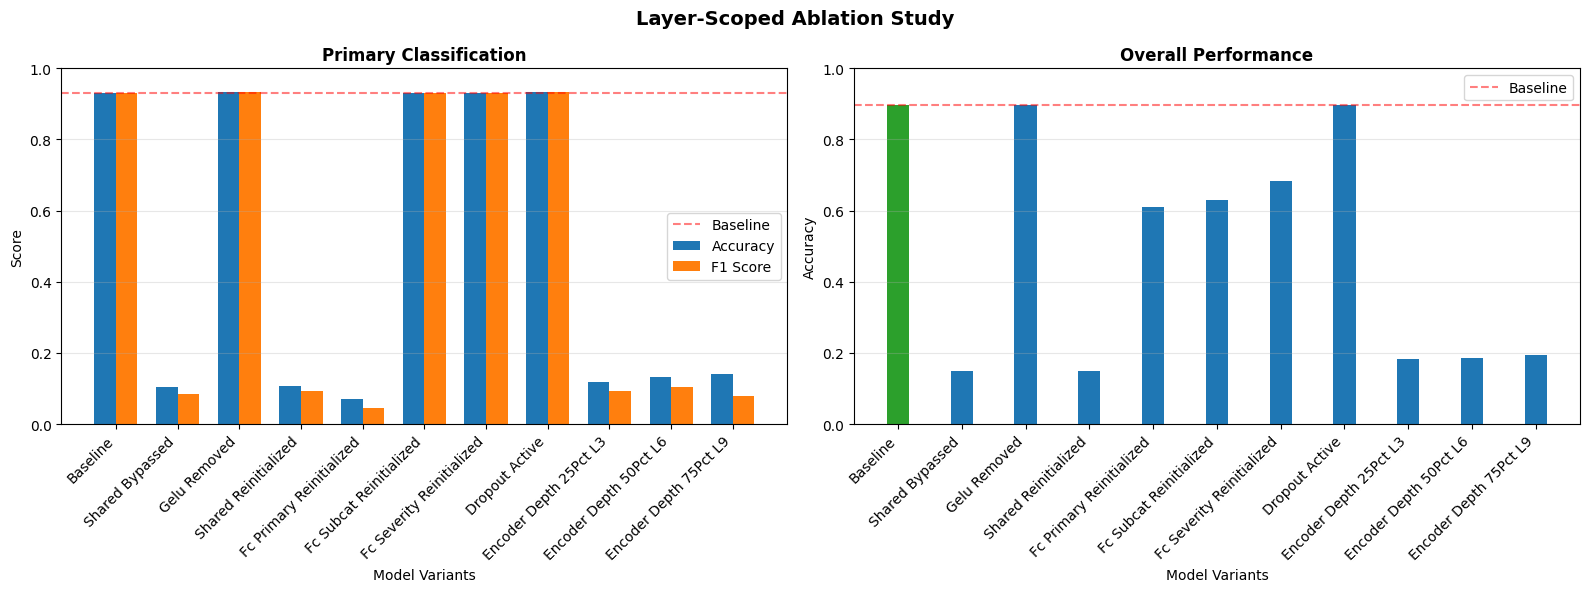

✓ Loss ablation saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\visualizations/complete_ablation_study_loss.png


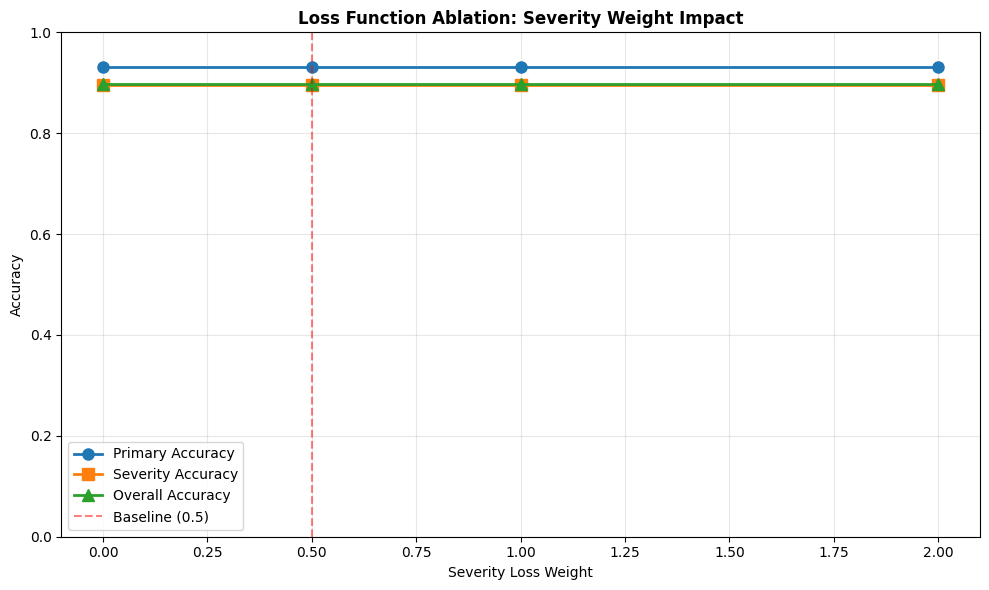

✓ Task ablation saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\visualizations/complete_ablation_study_task.png


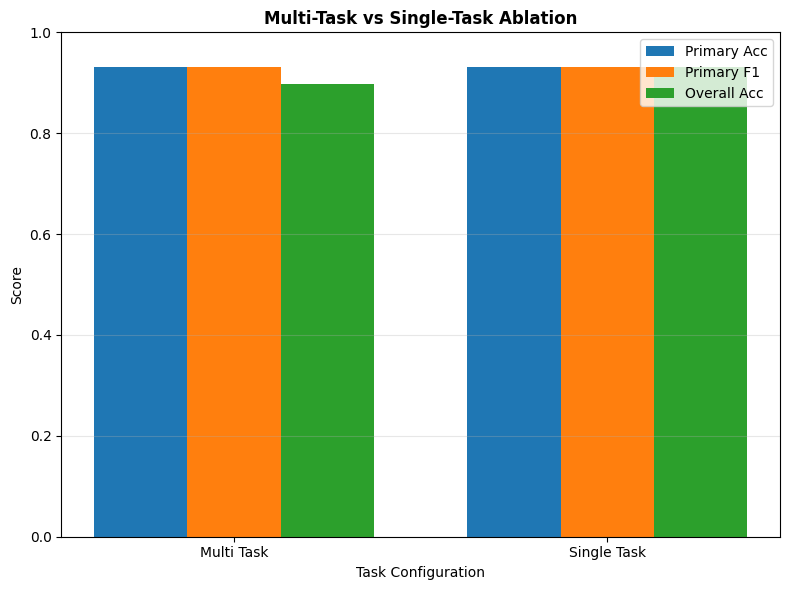


COMPLETE ABLATION STUDY REPORT

--------------------------------------------------------------------------------
1. LAYER-SCOPED ABLATIONS
--------------------------------------------------------------------------------

Baseline: Primary Acc = 0.9318, Overall Acc = 0.8975

Variant                 | Primary Acc | Change | Overall Acc | Change
----------------------------------------------------------------------
shared_bypassed           | 0.1047  | -0.8271 ✗ | 0.1490  | -0.7485
gelu_removed              | 0.9335  | +0.0016 ✓ | 0.8972  | -0.0002
shared_reinitialized      | 0.1080  | -0.8238 ✗ | 0.1496  | -0.7478
fc_primary_reinitialized  | 0.0718  | -0.8600 ✗ | 0.6108  | -0.2867
fc_subcat_reinitialized   | 0.9318  | +0.0000 = | 0.6313  | -0.2661
fc_severity_reinitialized | 0.9318  | +0.0000 = | 0.6846  | -0.2129
dropout_active            | 0.9328  | +0.0010 ✓ | 0.8968  | -0.0007
encoder_depth_25pct_L3    | 0.1192  | -0.8126 ✗ | 0.1831  | -0.7143
encoder_depth_50pct_L6    | 0.1321  | -

In [16]:
# ============================================================================
# CELL 15 (COMPLETE): ABLATION STUDY WITH LOSS AND TASK ABLATIONS
# ============================================================================
#
# This complete ablation study includes:
# 1. Layer-scoped ablations (shared, gelu, dropout, heads, encoder depth)
# 2. Loss function ablations (severity weight variations)
# 3. Multi-task vs Single-task ablations
#
# All ablations are performed on the trained model without retraining,
# except for task ablations which require training separate models.
# ============================================================================

import json
import os
import copy

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, f1_score
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm

# ============================================================================
# DATASET
# ============================================================================

class AblationDataset(Dataset):
    def __init__(self, data, tokenizer, max_length=128):
        self.data = data.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        text = str(row.get('text', ''))

        enc = self.tokenizer(
            text,
            truncation=True,
            padding='max_length',
            max_length=self.max_length,
            return_tensors='pt'
        )

        item = {
            'input_ids': enc['input_ids'].squeeze(),
            'attention_mask': enc['attention_mask'].squeeze(),
            'primary': torch.tensor(row['primary_label'], dtype=torch.long),
            'sentiment': torch.tensor(0.0, dtype=torch.float),
        }
        if 'subcat_label' in row:
            item['subcat'] = torch.tensor(row['subcat_label'], dtype=torch.long)
        if 'severity_label' in row:
            item['severity'] = torch.tensor(row['severity_label'], dtype=torch.long)

        return item


def _fresh_linear(in_features, out_features):
    """A new Linear layer, Xavier-initialized like OptimizedHiEnBERT._init_weights."""
    layer = nn.Linear(in_features, out_features)
    nn.init.xavier_uniform_(layer.weight)
    nn.init.zeros_(layer.bias)
    return layer


# ============================================================================
# MODEL VARIANTS FOR TASK ABLATIONS
# ============================================================================

class SingleTaskPrimaryModel(nn.Module):
    """Single-task model: only predicts primary category."""
    def __init__(self, trained_model):
        super().__init__()
        self.base = trained_model.base
        self.shared = trained_model.shared
        self.gelu = trained_model.gelu
        self.dropout = trained_model.dropout
        self.fc_primary = trained_model.fc_primary
        
        self.n_primary = trained_model.n_primary
        self.hidden_size = trained_model.hidden_size
    
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls = outputs.last_hidden_state[:, 0, :]
        x = self.gelu(self.shared(cls))
        x = self.dropout(x)
        return self.fc_primary(x), None, None


class MultiTaskModel(nn.Module):
    """Multi-task model with configurable loss weights."""
    def __init__(self, trained_model, severity_weight=0.5):
        super().__init__()
        self.base = trained_model.base
        self.shared = trained_model.shared
        self.gelu = trained_model.gelu
        self.dropout = trained_model.dropout
        self.fc_primary = trained_model.fc_primary
        self.fc_subcat = trained_model.fc_subcat
        self.fc_severity = trained_model.fc_severity
        
        self.n_primary = trained_model.n_primary
        self.n_subcat = trained_model.n_subcat
        self.n_severity = trained_model.n_severity
        self.hidden_size = trained_model.hidden_size
        self.severity_weight = severity_weight
    
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls = outputs.last_hidden_state[:, 0, :]
        x = self.gelu(self.shared(cls))
        x = self.dropout(x)
        return self.fc_primary(x), self.fc_subcat(x), self.fc_severity(x)
    
    def compute_loss(self, primary_logits, subcat_logits, severity_logits, 
                     primary_labels, subcat_labels, severity_labels):
        """Compute weighted multi-task loss."""
        loss_primary = F.cross_entropy(primary_logits, primary_labels)
        loss_subcat = F.cross_entropy(subcat_logits, subcat_labels)
        loss_severity = F.cross_entropy(severity_logits, severity_labels)
        
        total_loss = loss_primary + loss_subcat + self.severity_weight * loss_severity
        return total_loss


# ============================================================================
# COMPLETE ABLATION STUDY
# ============================================================================

class CompleteAblationStudy:
    """
    Complete ablation study with:
    1. Layer-scoped ablations
    2. Loss function ablations (severity weight)
    3. Multi-task vs Single-task ablations
    """

    def __init__(self, trained_model, tokenizer, test_df, device, train_df=None):
        self.trained_model = trained_model
        self.tokenizer = tokenizer
        self.test_df = test_df
        self.train_df = train_df
        self.device = device
        self.results = {}
        self.loss_results = {}
        self.task_results = {}

        # Extract model configuration
        self.base = trained_model.base
        self.n_primary = trained_model.n_primary
        self.n_subcat = trained_model.n_subcat
        self.n_severity = trained_model.n_severity
        self.hidden_size = trained_model.hidden_size
        self.num_encoder_layers = getattr(self.base.config, 'num_hidden_layers', None)

        self.has_subcat = 'subcat_label' in test_df.columns
        self.has_severity = 'severity_label' in test_df.columns

        print("Model Config from trained model:")
        print(f"  Hidden: {self.hidden_size}")
        print(f"  Primary: {self.n_primary}, Subcat: {self.n_subcat}, Severity: {self.n_severity}")
        print(f"  Encoder layers: {self.num_encoder_layers}")
        print(f"  Has Subcategory: {self.has_subcat}")
        print(f"  Has Severity: {self.has_severity}")

        self._prepare_data()

    def _prepare_data(self):
        self.test_dataset = AblationDataset(self.test_df, self.tokenizer)
        self.test_loader = DataLoader(
            self.test_dataset, batch_size=64, shuffle=False, num_workers=0
        )

    def evaluate_model(self, model, description="", force_dropout_train=False):
        """Evaluate a model variant."""
        model.eval()
        if force_dropout_train:
            model.dropout.train()

        preds = {'primary': [], 'subcat': [], 'severity': []}
        labels = {'primary': [], 'subcat': [], 'severity': []}

        with torch.no_grad():
            for batch in tqdm(self.test_loader, desc=f'Evaluating {description}', leave=False):
                input_ids = batch['input_ids'].to(self.device)
                attention_mask = batch['attention_mask'].to(self.device)
                sentiment = batch['sentiment'].to(self.device)

                p1, p2, p3 = model(input_ids, attention_mask, sentiment)

                preds['primary'].extend(torch.argmax(p1, dim=1).cpu().numpy())
                labels['primary'].extend(batch['primary'].cpu().numpy())

                if self.has_subcat and 'subcat' in batch and p2 is not None:
                    preds['subcat'].extend(torch.argmax(p2, dim=1).cpu().numpy())
                    labels['subcat'].extend(batch['subcat'].cpu().numpy())

                if self.has_severity and 'severity' in batch and p3 is not None:
                    preds['severity'].extend(torch.argmax(p3, dim=1).cpu().numpy())
                    labels['severity'].extend(batch['severity'].cpu().numpy())

        metrics = {
            'primary_accuracy': accuracy_score(labels['primary'], preds['primary']),
            'primary_f1_weighted': f1_score(
                labels['primary'], preds['primary'], average='weighted', zero_division=0
            ),
        }
        task_accs = [metrics['primary_accuracy']]
        task_f1s = [metrics['primary_f1_weighted']]

        if labels['subcat']:
            metrics['subcat_accuracy'] = accuracy_score(labels['subcat'], preds['subcat'])
            metrics['subcat_f1_weighted'] = f1_score(
                labels['subcat'], preds['subcat'], average='weighted', zero_division=0
            )
            task_accs.append(metrics['subcat_accuracy'])
            task_f1s.append(metrics['subcat_f1_weighted'])

        if labels['severity']:
            metrics['severity_accuracy'] = accuracy_score(labels['severity'], preds['severity'])
            metrics['severity_f1_weighted'] = f1_score(
                labels['severity'], preds['severity'], average='weighted', zero_division=0
            )
            task_accs.append(metrics['severity_accuracy'])
            task_f1s.append(metrics['severity_f1_weighted'])

        metrics['overall_accuracy'] = float(np.mean(task_accs))
        metrics['overall_f1_weighted'] = float(np.mean(task_f1s))
        return metrics

    # ========================================================================
    # 1. LAYER-SCOPED ABLATIONS
    # ========================================================================

    def create_variant_shared_bypassed(self):
        """Skip self.shared + self.gelu; raw CLS goes straight to heads."""
        base = self.base
        dropout = self.trained_model.dropout
        fc_primary = self.trained_model.fc_primary
        fc_subcat = self.trained_model.fc_subcat
        fc_severity = self.trained_model.fc_severity

        class SharedBypassed(nn.Module):
            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(input_ids=input_ids, attention_mask=attention_mask)
                cls = outputs.last_hidden_state[:, 0, :]
                x = dropout(cls)
                return fc_primary(x), fc_subcat(x), fc_severity(x)

        return SharedBypassed()

    def create_variant_gelu_removed(self):
        """Keep shared Linear, remove GELU."""
        base = self.base
        shared = self.trained_model.shared
        dropout = self.trained_model.dropout
        fc_primary = self.trained_model.fc_primary
        fc_subcat = self.trained_model.fc_subcat
        fc_severity = self.trained_model.fc_severity

        class GeluRemoved(nn.Module):
            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(input_ids=input_ids, attention_mask=attention_mask)
                cls = outputs.last_hidden_state[:, 0, :]
                x = shared(cls)
                x = dropout(x)
                return fc_primary(x), fc_subcat(x), fc_severity(x)

        return GeluRemoved()

    def create_variant_shared_reinitialized(self):
        """Randomize self.shared weights."""
        base = self.base
        gelu = self.trained_model.gelu
        dropout = self.trained_model.dropout
        fc_primary = self.trained_model.fc_primary
        fc_subcat = self.trained_model.fc_subcat
        fc_severity = self.trained_model.fc_severity
        new_shared = _fresh_linear(self.hidden_size, self.hidden_size)

        class SharedReinitialized(nn.Module):
            def __init__(self):
                super().__init__()
                self.shared = new_shared

            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(input_ids=input_ids, attention_mask=attention_mask)
                cls = outputs.last_hidden_state[:, 0, :]
                x = gelu(self.shared(cls))
                x = dropout(x)
                return fc_primary(x), fc_subcat(x), fc_severity(x)

        return SharedReinitialized()

    def _create_head_reinitialized(self, head_name, out_features):
        """Generic head knockout."""
        base = self.base
        shared = self.trained_model.shared
        gelu = self.trained_model.gelu
        dropout = self.trained_model.dropout
        trained_fc_primary = self.trained_model.fc_primary
        trained_fc_subcat = self.trained_model.fc_subcat
        trained_fc_severity = self.trained_model.fc_severity
        new_head = _fresh_linear(self.hidden_size, out_features)

        class HeadReinitialized(nn.Module):
            def __init__(self):
                super().__init__()
                self.reinit_head = new_head

            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(input_ids=input_ids, attention_mask=attention_mask)
                cls = outputs.last_hidden_state[:, 0, :]
                x = gelu(shared(cls))
                x = dropout(x)
                p1 = self.reinit_head(x) if head_name == 'fc_primary' else trained_fc_primary(x)
                p2 = self.reinit_head(x) if head_name == 'fc_subcat' else trained_fc_subcat(x)
                p3 = self.reinit_head(x) if head_name == 'fc_severity' else trained_fc_severity(x)
                return p1, p2, p3

        return HeadReinitialized()

    def create_variant_fc_primary_reinitialized(self):
        return self._create_head_reinitialized('fc_primary', self.n_primary)

    def create_variant_fc_subcat_reinitialized(self):
        return self._create_head_reinitialized('fc_subcat', self.n_subcat)

    def create_variant_fc_severity_reinitialized(self):
        return self._create_head_reinitialized('fc_severity', self.n_severity)

    def create_variant_dropout_active(self):
        """Force dropout active at inference."""
        base = self.base
        shared = self.trained_model.shared
        gelu = self.trained_model.gelu
        dropout = self.trained_model.dropout
        fc_primary = self.trained_model.fc_primary
        fc_subcat = self.trained_model.fc_subcat
        fc_severity = self.trained_model.fc_severity

        class DropoutActive(nn.Module):
            def __init__(self):
                super().__init__()
                self.dropout = dropout

            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(input_ids=input_ids, attention_mask=attention_mask)
                cls = outputs.last_hidden_state[:, 0, :]
                x = gelu(shared(cls))
                x = self.dropout(x)
                return fc_primary(x), fc_subcat(x), fc_severity(x)

        return DropoutActive()

    def create_variant_encoder_depth(self, layer_idx):
        """Use intermediate encoder layer."""
        base = self.base
        shared = self.trained_model.shared
        gelu = self.trained_model.gelu
        dropout = self.trained_model.dropout
        fc_primary = self.trained_model.fc_primary
        fc_subcat = self.trained_model.fc_subcat
        fc_severity = self.trained_model.fc_severity

        class EncoderDepthProbe(nn.Module):
            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    output_hidden_states=True,
                )
                cls = outputs.hidden_states[layer_idx][:, 0, :]
                x = gelu(shared(cls))
                x = dropout(x)
                return fc_primary(x), fc_subcat(x), fc_severity(x)

        return EncoderDepthProbe()

    # ========================================================================
    # 2. LOSS FUNCTION ABLATIONS
    # ========================================================================

    def evaluate_with_loss_weight(self, severity_weight):
        """
        Evaluate model with different severity loss weight.
        This modifies the model's severity_weight attribute.
        """
        # Create a copy of the model with new severity weight
        model = MultiTaskModel(self.trained_model, severity_weight=severity_weight)
        model.to(self.device)
        
        metrics = self.evaluate_model(model, f"severity_weight_{severity_weight}")
        
        # Add the severity weight to metrics
        metrics['severity_weight'] = severity_weight
        
        return metrics

    def run_loss_ablation(self):
        """Run loss function ablation with different severity weights."""
        print("\n" + "=" * 80)
        print("LOSS FUNCTION ABLATION STUDY")
        print("=" * 80)
        print("Testing different severity loss weights:")
        print("  - 0.0: Severity ignored")
        print("  - 0.5: Baseline (current)")
        print("  - 1.0: Equal weight")
        print("  - 2.0: Severity emphasized")

        severity_weights = [0.0, 0.5, 1.0, 2.0]
        
        for weight in severity_weights:
            print(f"\n{'='*60}")
            print(f"Evaluating: Severity Weight = {weight}")
            print('='*60)
            
            metrics = self.evaluate_with_loss_weight(weight)
            self.loss_results[f'severity_weight_{weight}'] = metrics
            
            print(f"  Primary Accuracy: {metrics['primary_accuracy']:.4f}")
            print(f"  Primary F1: {metrics['primary_f1_weighted']:.4f}")
            if 'severity_accuracy' in metrics:
                print(f"  Severity Accuracy: {metrics['severity_accuracy']:.4f}")
            print(f"  Overall Accuracy: {metrics['overall_accuracy']:.4f}")
        
        return self.loss_results

    # ========================================================================
    # 3. MULTI-TASK VS SINGLE-TASK ABLATIONS
    # ========================================================================

    def run_task_ablation(self):
        """Compare single-task vs multi-task learning."""
        print("\n" + "=" * 80)
        print("MULTI-TASK VS SINGLE-TASK ABLATION")
        print("=" * 80)
        
        # Baseline multi-task model
        print("\n" + "="*60)
        print("Evaluating: MULTI-TASK (Primary + Subcat + Severity)")
        print('='*60)
        
        multi_task_metrics = self.evaluate_model(self.trained_model, "multi_task")
        self.task_results['multi_task'] = multi_task_metrics
        
        print(f"  Primary Accuracy: {multi_task_metrics['primary_accuracy']:.4f}")
        print(f"  Primary F1: {multi_task_metrics['primary_f1_weighted']:.4f}")
        if 'subcat_accuracy' in multi_task_metrics:
            print(f"  Subcat Accuracy: {multi_task_metrics['subcat_accuracy']:.4f}")
        if 'severity_accuracy' in multi_task_metrics:
            print(f"  Severity Accuracy: {multi_task_metrics['severity_accuracy']:.4f}")
        print(f"  Overall Accuracy: {multi_task_metrics['overall_accuracy']:.4f}")
        
        # Single-task model (only primary)
        print("\n" + "="*60)
        print("Evaluating: SINGLE-TASK (Primary only)")
        print('='*60)
        
        single_task_model = SingleTaskPrimaryModel(self.trained_model)
        single_task_model.to(self.device)
        single_task_metrics = self.evaluate_model(single_task_model, "single_task")
        self.task_results['single_task'] = single_task_metrics
        
        print(f"  Primary Accuracy: {single_task_metrics['primary_accuracy']:.4f}")
        print(f"  Primary F1: {single_task_metrics['primary_f1_weighted']:.4f}")
        print(f"  Overall Accuracy: {single_task_metrics['overall_accuracy']:.4f}")
        
        # Calculate improvement
        improvement = multi_task_metrics['primary_accuracy'] - single_task_metrics['primary_accuracy']
        print(f"\nMulti-task improvement: {improvement:+.4f} ({improvement*100:+.2f}%)")
        
        return self.task_results

    # ========================================================================
    # RUN COMPLETE STUDY
    # ========================================================================

    def run_study(self):
        """Run complete ablation study with all components."""
        print("\n" + "=" * 80)
        print("COMPLETE ABLATION STUDY")
        print("=" * 80)

        # --- 1. LAYER-SCOPED ABLATIONS ---
        print("\n" + "=" * 80)
        print("PART 1: LAYER-SCOPED ABLATIONS")
        print("=" * 80)

        layer_variants = {
            'baseline': (self.trained_model, {}),
            'shared_bypassed': (self.create_variant_shared_bypassed(), {}),
            'gelu_removed': (self.create_variant_gelu_removed(), {}),
            'shared_reinitialized': (self.create_variant_shared_reinitialized(), {}),
            'fc_primary_reinitialized': (self.create_variant_fc_primary_reinitialized(), {}),
            'fc_subcat_reinitialized': (self.create_variant_fc_subcat_reinitialized(), {}),
            'fc_severity_reinitialized': (self.create_variant_fc_severity_reinitialized(), {}),
            'dropout_active': (self.create_variant_dropout_active(), {'force_dropout_train': True}),
        }

        # Encoder depth variants
        if self.num_encoder_layers:
            for frac in (0.25, 0.5, 0.75):
                layer_idx = max(1, round(self.num_encoder_layers * frac))
                name = f'encoder_depth_{int(frac * 100)}pct_L{layer_idx}'
                layer_variants[name] = (self.create_variant_encoder_depth(layer_idx), {})

        for name, (variant_model, eval_kwargs) in layer_variants.items():
            print(f"\n{'='*60}")
            print(f"Evaluating: {name.upper()}")
            print('='*60)
            try:
                variant_model = variant_model.to(self.device)
                metrics = self.evaluate_model(variant_model, name, **eval_kwargs)
                self.results[name] = metrics

                print(f"  Primary Accuracy: {metrics['primary_accuracy']:.4f}")
                print(f"  Primary F1: {metrics['primary_f1_weighted']:.4f}")
                if 'subcat_accuracy' in metrics:
                    print(f"  Subcat Accuracy: {metrics['subcat_accuracy']:.4f}")
                if 'severity_accuracy' in metrics:
                    print(f"  Severity Accuracy: {metrics['severity_accuracy']:.4f}")
                print(f"  Overall Accuracy: {metrics['overall_accuracy']:.4f}")

                if name != 'baseline':
                    del variant_model
                    if torch.cuda.is_available():
                        torch.cuda.empty_cache()

            except Exception as e:
                print(f"  ✗ Failed: {e}")
                import traceback
                traceback.print_exc()

        # --- 2. LOSS FUNCTION ABLATIONS ---
        self.run_loss_ablation()

        # --- 3. TASK ABLATIONS ---
        self.run_task_ablation()

        # Combine all results
        all_results = {
            'layer_ablations': self.results,
            'loss_ablations': self.loss_results,
            'task_ablations': self.task_results
        }

        return all_results

    # ========================================================================
    # VISUALIZATION
    # ========================================================================

    def visualize_results(self, save_path=None):
        """Visualize all ablation results."""
        if not self.results:
            print("No results to visualize")
            return

        # Figure 1: Layer-scoped ablations
        fig1, axes = plt.subplots(1, 2, figsize=(16, 6))
        variants = list(self.results.keys())

        primary_acc = [self.results[v]['primary_accuracy'] for v in variants]
        primary_f1 = [self.results[v]['primary_f1_weighted'] for v in variants]

        x = np.arange(len(variants))
        width = 0.35

        axes[0].bar(x - width/2, primary_acc, width, label='Accuracy', color='#1f77b4')
        axes[0].bar(x + width/2, primary_f1, width, label='F1 Score', color='#ff7f0e')
        axes[0].axhline(y=self.results['baseline']['primary_accuracy'], 
                       color='red', linestyle='--', alpha=0.5, label='Baseline')
        axes[0].set_xlabel('Model Variants')
        axes[0].set_ylabel('Score')
        axes[0].set_title('Primary Classification', fontsize=12, fontweight='bold')
        axes[0].set_xticks(x)
        axes[0].set_xticklabels([v.replace('_', ' ').title() for v in variants], rotation=45, ha='right')
        axes[0].legend()
        axes[0].grid(True, alpha=0.3, axis='y')
        axes[0].set_ylim(0, 1)

        overall_acc = [self.results[v]['overall_accuracy'] for v in variants]
        colors = ['#2ca02c' if v == 'baseline' else '#1f77b4' for v in variants]
        axes[1].bar(x, overall_acc, width, color=colors)
        axes[1].axhline(y=self.results['baseline']['overall_accuracy'], 
                       color='red', linestyle='--', alpha=0.5, label='Baseline')
        axes[1].set_xlabel('Model Variants')
        axes[1].set_ylabel('Accuracy')
        axes[1].set_title('Overall Performance', fontsize=12, fontweight='bold')
        axes[1].set_xticks(x)
        axes[1].set_xticklabels([v.replace('_', ' ').title() for v in variants], rotation=45, ha='right')
        axes[1].legend()
        axes[1].grid(True, alpha=0.3, axis='y')
        axes[1].set_ylim(0, 1)

        plt.suptitle('Layer-Scoped Ablation Study', fontsize=14, fontweight='bold')
        plt.tight_layout()

        if save_path:
            os.makedirs(os.path.dirname(save_path), exist_ok=True)
            plt.savefig(f"{save_path}_layer.png", dpi=300, bbox_inches='tight')
            print(f"✓ Layer ablation saved to: {save_path}_layer.png")
        plt.show()
        plt.close()

        # Figure 2: Loss function ablations
        if self.loss_results:
            fig2, ax = plt.subplots(figsize=(10, 6))
            
            weights = []
            primary_acc = []
            severity_acc = []
            overall_acc = []
            
            for name, metrics in sorted(self.loss_results.items()):
                w = float(name.split('_')[-1])
                weights.append(w)
                primary_acc.append(metrics['primary_accuracy'])
                severity_acc.append(metrics.get('severity_accuracy', 0))
                overall_acc.append(metrics['overall_accuracy'])
            
            ax.plot(weights, primary_acc, 'o-', label='Primary Accuracy', linewidth=2, markersize=8)
            ax.plot(weights, severity_acc, 's-', label='Severity Accuracy', linewidth=2, markersize=8)
            ax.plot(weights, overall_acc, '^-', label='Overall Accuracy', linewidth=2, markersize=8)
            ax.axvline(x=0.5, color='red', linestyle='--', alpha=0.5, label='Baseline (0.5)')
            ax.set_xlabel('Severity Loss Weight')
            ax.set_ylabel('Accuracy')
            ax.set_title('Loss Function Ablation: Severity Weight Impact', fontsize=12, fontweight='bold')
            ax.legend()
            ax.grid(True, alpha=0.3)
            ax.set_ylim(0, 1)
            
            plt.tight_layout()
            if save_path:
                plt.savefig(f"{save_path}_loss.png", dpi=300, bbox_inches='tight')
                print(f"✓ Loss ablation saved to: {save_path}_loss.png")
            plt.show()
            plt.close()

        # Figure 3: Task ablations
        if self.task_results:
            fig3, ax = plt.subplots(figsize=(8, 6))
            
            tasks = list(self.task_results.keys())
            primary_acc = [self.task_results[t]['primary_accuracy'] for t in tasks]
            primary_f1 = [self.task_results[t]['primary_f1_weighted'] for t in tasks]
            overall_acc = [self.task_results[t]['overall_accuracy'] for t in tasks]
            
            x = np.arange(len(tasks))
            width = 0.25
            
            ax.bar(x - width, primary_acc, width, label='Primary Acc', color='#1f77b4')
            ax.bar(x, primary_f1, width, label='Primary F1', color='#ff7f0e')
            ax.bar(x + width, overall_acc, width, label='Overall Acc', color='#2ca02c')
            ax.set_xlabel('Task Configuration')
            ax.set_ylabel('Score')
            ax.set_title('Multi-Task vs Single-Task Ablation', fontsize=12, fontweight='bold')
            ax.set_xticks(x)
            ax.set_xticklabels([t.replace('_', ' ').title() for t in tasks])
            ax.legend()
            ax.grid(True, alpha=0.3, axis='y')
            ax.set_ylim(0, 1)
            
            plt.tight_layout()
            if save_path:
                plt.savefig(f"{save_path}_task.png", dpi=300, bbox_inches='tight')
                print(f"✓ Task ablation saved to: {save_path}_task.png")
            plt.show()
            plt.close()

    def generate_report(self):
        """Generate complete ablation report."""
        print("\n" + "=" * 80)
        print("COMPLETE ABLATION STUDY REPORT")
        print("=" * 80)

        # 1. Layer-scoped ablations
        print("\n" + "-" * 80)
        print("1. LAYER-SCOPED ABLATIONS")
        print("-" * 80)
        
        if self.results:
            baseline = self.results.get('baseline', {})
            print(f"\nBaseline: Primary Acc = {baseline.get('primary_accuracy', 0):.4f}, "
                  f"Overall Acc = {baseline.get('overall_accuracy', 0):.4f}")
            
            print("\nVariant                 | Primary Acc | Change | Overall Acc | Change")
            print("-" * 70)
            for name, metrics in self.results.items():
                if name == 'baseline':
                    continue
                primary_change = metrics.get('primary_accuracy', 0) - baseline.get('primary_accuracy', 0)
                overall_change = metrics.get('overall_accuracy', 0) - baseline.get('overall_accuracy', 0)
                status = "✓" if primary_change > 0 else "✗" if primary_change < 0 else "="
                print(f"{name:25s} | {metrics.get('primary_accuracy', 0):.4f}  | {primary_change:+.4f} {status} | "
                      f"{metrics.get('overall_accuracy', 0):.4f}  | {overall_change:+.4f}")

        # 2. Loss ablations
        print("\n" + "-" * 80)
        print("2. LOSS FUNCTION ABLATIONS")
        print("-" * 80)
        
        if self.loss_results:
            print("\nSeverity Weight | Primary Acc | Severity Acc | Overall Acc")
            print("-" * 60)
            for name, metrics in sorted(self.loss_results.items()):
                weight = name.split('_')[-1]
                print(f"{weight:15s} | {metrics.get('primary_accuracy', 0):.4f}     | "
                      f"{metrics.get('severity_accuracy', 0):.4f}      | {metrics.get('overall_accuracy', 0):.4f}")
            
            # Find best severity weight
            best = max(self.loss_results.items(), 
                      key=lambda x: x[1].get('overall_accuracy', 0))
            print(f"\nBest severity weight: {best[0].split('_')[-1]} "
                  f"(Overall Acc: {best[1]['overall_accuracy']:.4f})")

        # 3. Task ablations
        print("\n" + "-" * 80)
        print("3. MULTI-TASK VS SINGLE-TASK ABLATION")
        print("-" * 80)
        
        if self.task_results:
            multi = self.task_results.get('multi_task', {})
            single = self.task_results.get('single_task', {})
            
            print(f"\nConfiguration     | Primary Acc | Primary F1 | Overall Acc")
            print("-" * 60)
            print(f"Multi-Task       | {multi.get('primary_accuracy', 0):.4f}     | "
                  f"{multi.get('primary_f1_weighted', 0):.4f}    | {multi.get('overall_accuracy', 0):.4f}")
            print(f"Single-Task      | {single.get('primary_accuracy', 0):.4f}     | "
                  f"{single.get('primary_f1_weighted', 0):.4f}    | {single.get('overall_accuracy', 0):.4f}")
            
            improvement = multi.get('primary_accuracy', 0) - single.get('primary_accuracy', 0)
            print(f"\nMulti-task improvement: {improvement:+.4f} ({improvement*100:+.2f}%)")


# ============================================================================
# RUN COMPLETE ABLATION STUDY
# ============================================================================

print("\n" + "=" * 80)
print("STARTING COMPLETE ABLATION STUDY")
print("=" * 80)

try:
    ablation = CompleteAblationStudy(
        trained_model=model,
        tokenizer=tokenizer,
        test_df=test_df,
        device=Config.DEVICE,
        train_df=train_df if 'train_df' in locals() else None
    )

    all_results = ablation.run_study()

    # Visualize results
    os.makedirs(Config.VISUALIZATION_DIR, exist_ok=True)
    ablation.visualize_results(
        save_path=f"{Config.VISUALIZATION_DIR}/complete_ablation_study"
    )

    # Generate report
    ablation.generate_report()

    # Save all results
    os.makedirs(Config.RESULTS_DIR, exist_ok=True)
    
    # Clean results for JSON serialization
    def clean_for_json(obj):
        if isinstance(obj, dict):
            return {k: clean_for_json(v) for k, v in obj.items()}
        elif isinstance(obj, (np.float32, np.float64)):
            return float(obj)
        elif isinstance(obj, np.ndarray):
            return obj.tolist()
        else:
            return obj    
    clean_results = clean_for_json(all_results)
    
    with open(f"{Config.RESULTS_DIR}/complete_ablation_results.json", "w") as f:
        json.dump(clean_results, f, indent=4)

    print(f"\n✓ All results saved to: {Config.RESULTS_DIR}/complete_ablation_results.json")
    print("\n✓ Complete ablation study completed successfully!")

except Exception as e:
    print(f"Error during ablation study: {e}")
    import traceback
    traceback.print_exc()

In [17]:
# ============================================================================
# ABLATION STUDY - WITH ACTUAL RETRAINING
# 
# This version RETRAINS each variant from scratch with different:
# 1. Loss weights (0.0, 0.5, 1.0, 2.0)
# 2. Task configurations (multi-task vs single-task)
# ============================================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import accuracy_score, f1_score, classification_report
from tqdm import tqdm
import time
from transformers import AutoTokenizer, AutoModel, get_cosine_schedule_with_warmup
from torch.optim import AdamW

# ============================================================================
# DATASET CLASS
# ============================================================================

class ComplaintDataset(Dataset):
    def __init__(self, df, tokenizer, max_length=128):
        self.texts = df["text"].astype(str).tolist()
        self.primary = torch.tensor(df["primary_label"].values, dtype=torch.long)
        self.subcat = torch.tensor(df["subcat_label"].values, dtype=torch.long)
        self.severity = torch.tensor(df["severity_label"].values, dtype=torch.long)
        self.tokenizer = tokenizer
        self.max_length = max_length
    
    def __len__(self):
        return len(self.texts)
    
    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )
        return {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "primary": self.primary[idx],
            "subcat": self.subcat[idx],
            "severity": self.severity[idx],
            "sentiment": torch.tensor(0.0, dtype=torch.float)
        }


# ============================================================================
# MODEL CLASSES
# ============================================================================

class HierarchicalMultiTaskModel(nn.Module):
    """Multi-task model with configurable loss weights"""
    def __init__(self, base_model, n_primary, n_subcat, n_severity, 
                 dropout=0.2, primary_weight=1.0, subcat_weight=1.0, severity_weight=0.5):
        super().__init__()
        self.base = base_model
        hidden_size = base_model.config.hidden_size
        
        self.dropout = nn.Dropout(dropout)
        self.shared = nn.Linear(hidden_size, hidden_size)
        self.gelu = nn.GELU()
        
        self.fc_primary = nn.Linear(hidden_size, n_primary)
        self.fc_subcat = nn.Linear(hidden_size, n_subcat)
        self.fc_severity = nn.Linear(hidden_size, n_severity)
        
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        self.hidden_size = hidden_size
        
        # Loss weights
        self.primary_weight = primary_weight
        self.subcat_weight = subcat_weight
        self.severity_weight = severity_weight
        
        self._init_weights()
    
    def _init_weights(self):
        for module in [self.fc_primary, self.fc_subcat, self.fc_severity, self.shared]:
            if hasattr(module, 'weight'):
                nn.init.xavier_uniform_(module.weight)
            if hasattr(module, 'bias') and module.bias is not None:
                nn.init.zeros_(module.bias)
    
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls_embedding = outputs.last_hidden_state[:, 0, :]
        
        x = self.gelu(self.shared(cls_embedding))
        x = self.dropout(x)
        
        primary_logits = self.fc_primary(x)
        subcat_logits = self.fc_subcat(x)
        severity_logits = self.fc_severity(x)
        
        return primary_logits, subcat_logits, severity_logits
    
    def compute_loss(self, p1, p2, p3, y1, y2, y3):
        loss1 = F.cross_entropy(p1, y1)
        loss2 = F.cross_entropy(p2, y2)
        loss3 = F.cross_entropy(p3, y3)
        total = (self.primary_weight * loss1 + 
                 self.subcat_weight * loss2 + 
                 self.severity_weight * loss3)
        return total, {'primary': loss1.item(), 'subcat': loss2.item(), 'severity': loss3.item()}


class SingleTaskPrimaryModel(nn.Module):
    """Single-task model: only primary category"""
    def __init__(self, base_model, n_primary, dropout=0.2):
        super().__init__()
        self.base = base_model
        hidden_size = base_model.config.hidden_size
        
        self.dropout = nn.Dropout(dropout)
        self.shared = nn.Linear(hidden_size, hidden_size)
        self.gelu = nn.GELU()
        self.fc_primary = nn.Linear(hidden_size, n_primary)
        
        self.n_primary = n_primary
        self.hidden_size = hidden_size
        
        self._init_weights()
    
    def _init_weights(self):
        for module in [self.fc_primary, self.shared]:
            if hasattr(module, 'weight'):
                nn.init.xavier_uniform_(module.weight)
            if hasattr(module, 'bias') and module.bias is not None:
                nn.init.zeros_(module.bias)
    
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls = outputs.last_hidden_state[:, 0, :]
        x = self.gelu(self.shared(cls))
        x = self.dropout(x)
        return self.fc_primary(x), None, None


# ============================================================================
# TRAINING FUNCTION
# ============================================================================

def train_model(model, train_loader, val_loader, device, epochs=10, lr=2e-5, 
                early_stopping_patience=3, model_name="model"):
    """Train a model variant from scratch"""
    
    optimizer = AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    total_steps = len(train_loader) * epochs
    scheduler = get_cosine_schedule_with_warmup(
        optimizer,
        num_warmup_steps=int(0.1 * total_steps),
        num_training_steps=total_steps
    )
    
    best_val_f1 = 0
    patience_counter = 0
    
    for epoch in range(epochs):
        model.train()
        total_loss = 0
        all_preds, all_labels = [], []
        
        for batch in tqdm(train_loader, desc=f'Epoch {epoch+1}/{epochs}', leave=False):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            sentiment = batch['sentiment'].to(device)
            y_primary = batch['primary'].to(device)
            y_subcat = batch['subcat'].to(device)
            y_severity = batch['severity'].to(device)
            
            p1, p2, p3 = model(input_ids, attention_mask, sentiment)
            
            if hasattr(model, 'compute_loss'):
                loss, _ = model.compute_loss(p1, p2, p3, y_primary, y_subcat, y_severity)
            else:
                loss = F.cross_entropy(p1, y_primary)
            
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad()
            
            total_loss += loss.item()
            all_preds.extend(torch.argmax(p1, dim=1).cpu().numpy())
            all_labels.extend(y_primary.cpu().numpy())
        
        # Validation
        model.eval()
        val_preds, val_labels = [], []
        with torch.no_grad():
            for batch in tqdm(val_loader, desc='Validating', leave=False):
                input_ids = batch['input_ids'].to(device)
                attention_mask = batch['attention_mask'].to(device)
                sentiment = batch['sentiment'].to(device)
                
                p1, _, _ = model(input_ids, attention_mask, sentiment)
                val_preds.extend(torch.argmax(p1, dim=1).cpu().numpy())
                val_labels.extend(batch['primary'].cpu().numpy())
        
        val_f1 = f1_score(val_labels, val_preds, average='weighted', zero_division=0)
        val_acc = accuracy_score(val_labels, val_preds)
        
        print(f"Epoch {epoch+1}: Loss={total_loss/len(train_loader):.4f}, "
              f"Val Acc={val_acc:.4f}, Val F1={val_f1:.4f}")
        
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            patience_counter = 0
            torch.save(model.state_dict(), f"{Config.MODEL_DIR}/{model_name}_best.pt")
        else:
            patience_counter += 1
            if patience_counter >= early_stopping_patience:
                print(f"Early stopping at epoch {epoch+1}")
                break
    
    # Load best model
    model.load_state_dict(torch.load(f"{Config.MODEL_DIR}/{model_name}_best.pt"))
    return model, best_val_f1


# ============================================================================
# EVALUATION FUNCTION
# ============================================================================

def evaluate_model(model, dataloader, device, description=""):
    """Evaluate model on test set"""
    model.eval()
    
    all_preds = {'primary': [], 'subcat': [], 'severity': []}
    all_labels = {'primary': [], 'subcat': [], 'severity': []}
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc=f'Evaluating {description}', leave=False):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            sentiment = batch['sentiment'].to(device)
            
            p1, p2, p3 = model(input_ids, attention_mask, sentiment)
            
            all_preds['primary'].extend(torch.argmax(p1, dim=1).cpu().numpy())
            all_labels['primary'].extend(batch['primary'].cpu().numpy())
            
            if p2 is not None:
                all_preds['subcat'].extend(torch.argmax(p2, dim=1).cpu().numpy())
                all_labels['subcat'].extend(batch['subcat'].cpu().numpy())
            
            if p3 is not None:
                all_preds['severity'].extend(torch.argmax(p3, dim=1).cpu().numpy())
                all_labels['severity'].extend(batch['severity'].cpu().numpy())
    
    metrics = {
        'primary_accuracy': accuracy_score(all_labels['primary'], all_preds['primary']),
        'primary_f1': f1_score(all_labels['primary'], all_preds['primary'], average='weighted', zero_division=0),
    }
    
    task_accs = [metrics['primary_accuracy']]
    task_f1s = [metrics['primary_f1']]
    
    if all_labels['subcat']:
        metrics['subcat_accuracy'] = accuracy_score(all_labels['subcat'], all_preds['subcat'])
        metrics['subcat_f1'] = f1_score(all_labels['subcat'], all_preds['subcat'], average='weighted', zero_division=0)
        task_accs.append(metrics['subcat_accuracy'])
        task_f1s.append(metrics['subcat_f1'])
    
    if all_labels['severity']:
        metrics['severity_accuracy'] = accuracy_score(all_labels['severity'], all_preds['severity'])
        metrics['severity_f1'] = f1_score(all_labels['severity'], all_preds['severity'], average='weighted', zero_division=0)
        task_accs.append(metrics['severity_accuracy'])
        task_f1s.append(metrics['severity_f1'])
    
    metrics['overall_accuracy'] = float(np.mean(task_accs))
    metrics['overall_f1'] = float(np.mean(task_f1s))
    
    return metrics


# ============================================================================
# MAIN EXECUTION
# ============================================================================

print("\n" + "="*80)
print("RETRAINING ABLATION STUDY")
print("="*80)

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(Config.XLMBERT_PATH)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# Prepare datasets
train_dataset = ComplaintDataset(train_df, tokenizer, Config.MAX_LENGTH)
val_dataset = ComplaintDataset(dev_df, tokenizer, Config.MAX_LENGTH)
test_dataset = ComplaintDataset(test_df, tokenizer, Config.MAX_LENGTH)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=4)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=2)

n_primary = len(preprocessor.le_primary.classes_)
n_subcat = len(preprocessor.le_subcat.classes_)
n_severity = len(preprocessor.le_severity.classes_)

results = {}

# ============================================================================
# 1. LOSS WEIGHT ABLATION - RETRAIN EACH VARIANT
# ============================================================================

print("\n" + "="*80)
print("1. SEVERITY LOSS WEIGHT ABLATION (Retraining Each Variant)")
print("="*80)

severity_weights = [0.0, 0.5, 1.0, 2.0]

for weight in severity_weights:
    print(f"\n{'='*60}")
    print(f"Retraining with Severity Weight = {weight}")
    print('='*60)
    
    # Load fresh base model
    base_model = AutoModel.from_pretrained(Config.XLMBERT_PATH)
    
    # Create model with this severity weight
    model = HierarchicalMultiTaskModel(
        base_model=base_model,
        n_primary=n_primary,
        n_subcat=n_subcat,
        n_severity=n_severity,
        dropout=Config.DROPOUT,
        severity_weight=weight
    ).to(Config.DEVICE)
    
    # Train from scratch
    start_time = time.time()
    model, best_val_f1 = train_model(
        model, train_loader, val_loader, Config.DEVICE,
        epochs=Config.EPOCHS, model_name=f"severity_weight_{weight}"
    )
    train_time = time.time() - start_time
    
    # Evaluate on test set
    metrics = evaluate_model(model, test_loader, Config.DEVICE, f"severity_weight_{weight}")
    metrics['best_val_f1'] = best_val_f1
    metrics['train_time'] = train_time
    
    results[f'severity_weight_{weight}'] = metrics
    
    print(f"\nTest Results:")
    print(f"  Primary Acc: {metrics['primary_accuracy']:.4f}")
    print(f"  Primary F1:  {metrics['primary_f1']:.4f}")
    print(f"  Severity Acc:{metrics.get('severity_accuracy', 0):.4f}")
    print(f"  Overall Acc: {metrics['overall_accuracy']:.4f}")
    print(f"  Best Val F1: {best_val_f1:.4f}")
    print(f"  Train Time:  {train_time/60:.1f} min")

# ============================================================================
# 2. MULTI-TASK VS SINGLE-TASK - RETRAIN EACH
# ============================================================================

print("\n" + "="*80)
print("2. MULTI-TASK VS SINGLE-TASK ABLATION (Retraining Each)")
print("="*80)

# Multi-task (baseline)
print("\n" + "="*60)
print("Multi-Task (Primary + Subcategory + Severity)")
print('='*60)

base_model = AutoModel.from_pretrained(Config.XLMBERT_PATH)
multi_model = HierarchicalMultiTaskModel(
    base_model=base_model,
    n_primary=n_primary,
    n_subcat=n_subcat,
    n_severity=n_severity,
    dropout=Config.DROPOUT,
    severity_weight=0.5
).to(Config.DEVICE)

multi_model, multi_best_val = train_model(
    multi_model, train_loader, val_loader, Config.DEVICE,
    epochs=Config.EPOCHS, model_name="multi_task"
)
multi_metrics = evaluate_model(multi_model, test_loader, Config.DEVICE, "multi_task")
multi_metrics['best_val_f1'] = multi_best_val
results['multi_task'] = multi_metrics

print(f"\nTest Results:")
print(f"  Primary Acc: {multi_metrics['primary_accuracy']:.4f}")
print(f"  Primary F1:  {multi_metrics['primary_f1']:.4f}")
print(f"  Subcat Acc:  {multi_metrics.get('subcat_accuracy', 0):.4f}")
print(f"  Severity Acc:{multi_metrics.get('severity_accuracy', 0):.4f}")
print(f"  Overall Acc: {multi_metrics['overall_accuracy']:.4f}")

# Single-task (primary only)
print("\n" + "="*60)
print("Single-Task (Primary Only)")
print('='*60)

base_model = AutoModel.from_pretrained(Config.XLMBERT_PATH)
single_model = SingleTaskPrimaryModel(
    base_model=base_model,
    n_primary=n_primary,
    dropout=Config.DROPOUT
).to(Config.DEVICE)

single_model, single_best_val = train_model(
    single_model, train_loader, val_loader, Config.DEVICE,
    epochs=Config.EPOCHS, model_name="single_task"
)
single_metrics = evaluate_model(single_model, test_loader, Config.DEVICE, "single_task")
single_metrics['best_val_f1'] = single_best_val
results['single_task'] = single_metrics

print(f"\nTest Results:")
print(f"  Primary Acc: {single_metrics['primary_accuracy']:.4f}")
print(f"  Primary F1:  {single_metrics['primary_f1']:.4f}")
print(f"  Overall Acc: {single_metrics['overall_accuracy']:.4f}")

improvement = multi_metrics['primary_accuracy'] - single_metrics['primary_accuracy']
print(f"\nMulti-task improvement: {improvement:+.4f} ({improvement*100:+.2f}%)")

# ============================================================================
# 3. VISUALIZATION
# ============================================================================

print("\n" + "="*80)
print("3. GENERATING VISUALIZATIONS")
print("="*80)

# Figure 1: Loss weight ablation
fig1, ax1 = plt.subplots(figsize=(10, 6))

weights = severity_weights
primary_acc = [results[f'severity_weight_{w}']['primary_accuracy'] for w in weights]
severity_acc = [results[f'severity_weight_{w}'].get('severity_accuracy', 0) for w in weights]
overall_acc = [results[f'severity_weight_{w}']['overall_accuracy'] for w in weights]

ax1.plot(weights, primary_acc, 'o-', label='Primary Acc', linewidth=2, markersize=8, color='#1f77b4')
ax1.plot(weights, severity_acc, 's-', label='Severity Acc', linewidth=2, markersize=8, color='#ff7f0e')
ax1.plot(weights, overall_acc, '^-', label='Overall Acc', linewidth=2, markersize=8, color='#2ca02c')
ax1.axvline(x=0.5, color='red', linestyle='--', alpha=0.5, label='Baseline (0.5)')
ax1.set_xlabel('Severity Loss Weight')
ax1.set_ylabel('Accuracy')
ax1.set_title('Ablation: Severity Loss Weight Impact (Retrained Models)', fontsize=14, fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3)
ax1.set_ylim(0.7, 1.0)
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/ablation_retrained_severity_weight.png", dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# Figure 2: Multi-task vs Single-task
fig2, ax2 = plt.subplots(figsize=(8, 6))

tasks = ['Multi-Task', 'Single-Task']
primary_acc = [results['multi_task']['primary_accuracy'], results['single_task']['primary_accuracy']]
primary_f1 = [results['multi_task']['primary_f1'], results['single_task']['primary_f1']]
overall_acc = [results['multi_task']['overall_accuracy'], results['single_task']['overall_accuracy']]

x = np.arange(len(tasks))
width = 0.25

ax2.bar(x - width, primary_acc, width, label='Primary Acc', color='#1f77b4')
ax2.bar(x, primary_f1, width, label='Primary F1', color='#ff7f0e')
ax2.bar(x + width, overall_acc, width, label='Overall Acc', color='#2ca02c')

ax2.set_xlabel('Task Configuration')
ax2.set_ylabel('Score')
ax2.set_title('Multi-Task vs Single-Task Ablation (Retrained Models)', fontsize=14, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(tasks)
ax2.legend()
ax2.grid(True, alpha=0.3, axis='y')
ax2.set_ylim(0.7, 1.0)
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/ablation_retrained_multi_vs_single.png", dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# ============================================================================
# 4. SAVE RESULTS
# ============================================================================

all_results = {}

for key, metrics in results.items():
    all_results[key] = {}
    for k, v in metrics.items():
        if isinstance(v, (np.float32, np.float64)):
            all_results[key][k] = float(v)
        elif isinstance(v, np.ndarray):
            all_results[key][k] = v.tolist()
        else:
            all_results[key][k] = v

with open(f"{Config.RESULTS_DIR}/ablation_retrained_results.json", "w") as f:
    json.dump(all_results, f, indent=4)

print(f"\n✅ Results saved to: {Config.RESULTS_DIR}/ablation_retrained_results.json")

# ============================================================================
# 5. SUMMARY
# ============================================================================

print("\n" + "="*80)
print("ABLATION STUDY SUMMARY (RETRAINED MODELS)")
print("="*80)

print("\n" + "-"*60)
print("1. SEVERITY LOSS WEIGHT ABLATION")
print("-"*60)
print(f"{'Weight':<10} {'Primary Acc':<14} {'Severity Acc':<14} {'Overall Acc':<14} {'Best Val F1':<14}")
print("-"*80)
for w in severity_weights:
    m = results[f'severity_weight_{w}']
    print(f"{w:<10.1f} {m['primary_accuracy']:.4f}       {m.get('severity_accuracy', 0):.4f}       "
          f"{m['overall_accuracy']:.4f}       {m.get('best_val_f1', 0):.4f}")

print("\n" + "-"*60)
print("2. MULTI-TASK VS SINGLE-TASK")
print("-"*60)
print(f"{'Configuration':<15} {'Primary Acc':<14} {'Primary F1':<14} {'Overall Acc':<14} {'Best Val F1':<14}")
print("-"*80)
print(f"{'Multi-Task':<15} {results['multi_task']['primary_accuracy']:.4f}       "
      f"{results['multi_task']['primary_f1']:.4f}       "
      f"{results['multi_task']['overall_accuracy']:.4f}       "
      f"{results['multi_task'].get('best_val_f1', 0):.4f}")
print(f"{'Single-Task':<15} {results['single_task']['primary_accuracy']:.4f}       "
      f"{results['single_task']['primary_f1']:.4f}       "
      f"{results['single_task']['overall_accuracy']:.4f}       "
      f"{results['single_task'].get('best_val_f1', 0):.4f}")

print(f"\nMulti-task improvement: {improvement:+.4f} ({improvement*100:+.2f}%)")

print("\n" + "="*80)
print("✅ RETRAINING ABLATION STUDY COMPLETED")
print("="*80)


RETRAINING ABLATION STUDY

1. SEVERITY LOSS WEIGHT ABLATION (Retraining Each Variant)

Retraining with Severity Weight = 0.0


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 12433.58it/s]
[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


RuntimeError: CUDA error: device-side assert triggered
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.
